# 카드사 고객 이탈 분석
**목적:** SQL DB에 저장된 카드사 고객 정보를 토대로 의사결정 지원  
**데이터:** BankChurners.csv (10,127건, 21개 컬럼)  
**단계:** CSV→MySQL 적재 → EDA → 심층분석 → 예측모델 → 보고서/PPT

---
## ▶ 사전 준비: 라이브러리 설치
처음 실행 시 아래 셀의 주석을 해제하고 실행하세요.

In [ ]:
%pip install pandas numpy matplotlib seaborn sqlalchemy pymysql scikit-learn xgboost imbalanced-learn python-docx python-pptx dotenv streamlit

---
# 📦 STAGE 1: CSV → MySQL 적재

In [4]:
import pandas as pd
import dotenv
from sqlalchemy import create_engine, text

from dotenv import load_dotenv
import os

load_dotenv()

MYSQL_USER = os.getenv('MYSQL_USER')
MYSQL_PASSWORD = os.getenv('MYSQL_PASSWORD')
MYSQL_HOST = os.getenv('MYSQL_HOST')
MYSQL_PORT = os.getenv('MYSQL_PORT', '3306')
MYSQL_DB = os.getenv('MYSQL_DB')
CSV_PATH = os.getenv('CSV_PATH')

# DB 생성 (없으면 자동 생성)
engine_root = create_engine(
    f'mysql+pymysql://{MYSQL_USER}:{MYSQL_PASSWORD}@{MYSQL_HOST}:{MYSQL_PORT}'
)
with engine_root.connect() as conn:
    conn.execute(text(f'CREATE DATABASE IF NOT EXISTS {MYSQL_DB} CHARACTER SET utf8mb4'))
    conn.commit()
print(f'✅ DB [{MYSQL_DB}] 준비 완료')

# CSV 로드
df = pd.read_csv(CSV_PATH)
print(f'✅ CSV 로드: {df.shape[0]:,}행 × {df.shape[1]}열')

# MySQL 적재
engine = create_engine(
    f'mysql+pymysql://{MYSQL_USER}:{MYSQL_PASSWORD}@{MYSQL_HOST}:{MYSQL_PORT}/{MYSQL_DB}'
)
df.to_sql('customers', con=engine, if_exists='replace', index=False)
print('✅ MySQL [customers] 테이블 적재 완료')

✅ DB [bankchurners] 준비 완료
✅ CSV 로드: 10,127행 × 21열
✅ MySQL [customers] 테이블 적재 완료


In [5]:
# MySQL에서 데이터 재조회 (이후 분석은 이 df 사용)
df = pd.read_sql('SELECT * FROM customers', con=engine)

# 이탈 여부 이진 변수 추가 (1=이탈, 0=유지)
df['Churned'] = (df['Attrition_Flag'] == 'Attrited Customer').astype(int)

print(df.shape)
df.head(3)

(10127, 22)


,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Churned
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0


---
# 🔍 STAGE 2: EDA (탐색적 데이터 분석)

## 2-1. 기초 통계 & 결측치 확인

### 📋 컬럼 설명

| 컬럼 | 설명 | 구분 |
|------|------|------|
| `Customer_Age` | 고객 나이 | 인구통계 |
| `Dependent_count` | 부양가족 수 | 인구통계 |
| `Months_on_book` | 카드 보유 기간 (개월) | 인구통계 |
| `Total_Relationship_Count` | 보유 금융상품 수 | 거래 행동 |
| `Months_Inactive_12_mon` | 최근 12개월 중 거래 없던 달 수 | 거래 행동 |
| `Contacts_Count_12_mon` | 최근 12개월 고객센터 연락 횟수 | 거래 행동 |
| `Credit_Limit` | 신용 한도 | 신용 |
| `Total_Revolving_Bal` | 리볼빙 잔액 (미결제 이월 금액) | 신용 |
| `Avg_Open_To_Buy` | 평균 잔여 한도 (12개월 평균) | 신용 |
| `Total_Amt_Chng_Q4_Q1` | 거래금액 변화율 (Q1 대비 Q4) | 거래 행동 |
| `Total_Trans_Amt` | 총 거래 금액 | 거래 행동 |
| `Total_Trans_Ct` | 총 거래 건수 | 거래 행동 |
| `Total_Ct_Chng_Q4_Q1` | 거래건수 변화율 (Q1 대비 Q4) | 거래 행동 |
| `Avg_Utilization_Ratio` | 평균 카드 이용률 (사용액 / 한도) | 신용 |

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# 한글 폰트 (Windows: 'Malgun Gothic', Mac: 'AppleGothic')
matplotlib.rc('font', family='Malgun Gothic')
matplotlib.rc('axes', unicode_minus=False)
plt.rcParams['figure.dpi'] = 120

print('=== 기초 통계 ===')
num_cols = ['Customer_Age', 'Dependent_count', 'Months_on_book',
            'Total_Relationship_Count', 'Months_Inactive_12_mon',
            'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal',
            'Avg_Open_To_Buy', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt',
            'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio']

print('=== 수치형 변수 기초통계 ===')
display(df[num_cols].describe().T.round(2))

# 범주형 변수 빈도
cat_cols = ['Attrition_Flag', 'Gender', 'Education_Level',
            'Marital_Status', 'Income_Category', 'Card_Category']

print('\n=== 범주형 변수 빈도 ===')
for col in cat_cols:
    print(f'\n[{col}]')
    print(df[col].value_counts())

print('\n=== 결측치 ===')
missing = df.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else '결측치 없음 ✅')

=== 기초 통계 ===
=== 수치형 변수 기초통계 ===


,count,mean,std,min,25%,50%,75%,max
Customer_Age,10127.0,46.33,8.02,26.0,41.00,46.00,52.00,73.00
Dependent_count,10127.0,2.35,1.30,0.0,1.00,2.00,3.00,5.00
Months_on_book,10127.0,35.93,7.99,13.0,31.00,36.00,40.00,56.00
Total_Relationship_Count,10127.0,3.81,1.55,1.0,3.00,4.00,5.00,6.00
Months_Inactive_12_mon,10127.0,2.34,1.01,0.0,2.00,2.00,3.00,6.00
Contacts_Count_12_mon,10127.0,2.46,1.11,0.0,2.00,2.00,3.00,6.00
Credit_Limit,10127.0,8631.95,9088.78,1438.3,2555.00,4549.00,11067.50,34516.00
Total_Revolving_Bal,10127.0,1162.81,814.99,0.0,359.00,1276.00,1784.00,2517.00
Avg_Open_To_Buy,10127.0,7469.14,9090.69,3.0,1324.50,3474.00,9859.00,34516.00
Total_Amt_Chng_Q4_Q1,10127.0,0.76,0.22,0.0,0.63,0.74,0.86,3.40



=== 범주형 변수 빈도 ===

[Attrition_Flag]
Attrition_Flag
Existing Customer    8500
Attrited Customer    1627
Name: count, dtype: int64

[Gender]
Gender
F    5358
M    4769
Name: count, dtype: int64

[Education_Level]
Education_Level
Graduate         3128
High School      2013
Unknown          1519
Uneducated       1487
College          1013
Post-Graduate     516
Doctorate         451
Name: count, dtype: int64

[Marital_Status]
Marital_Status
Married     4687
Single      3943
Unknown      749
Divorced     748
Name: count, dtype: int64

[Income_Category]
Income_Category
Less than $40K    3561
$40K - $60K       1790
$80K - $120K      1535
$60K - $80K       1402
Unknown           1112
$120K +            727
Name: count, dtype: int64

[Card_Category]
Card_Category
Blue        9436
Silver       555
Gold         116
Platinum      20
Name: count, dtype: int64

=== 결측치 ===
결측치 없음 ✅


## 2-2. 이탈률 현황 (핵심 KPI)

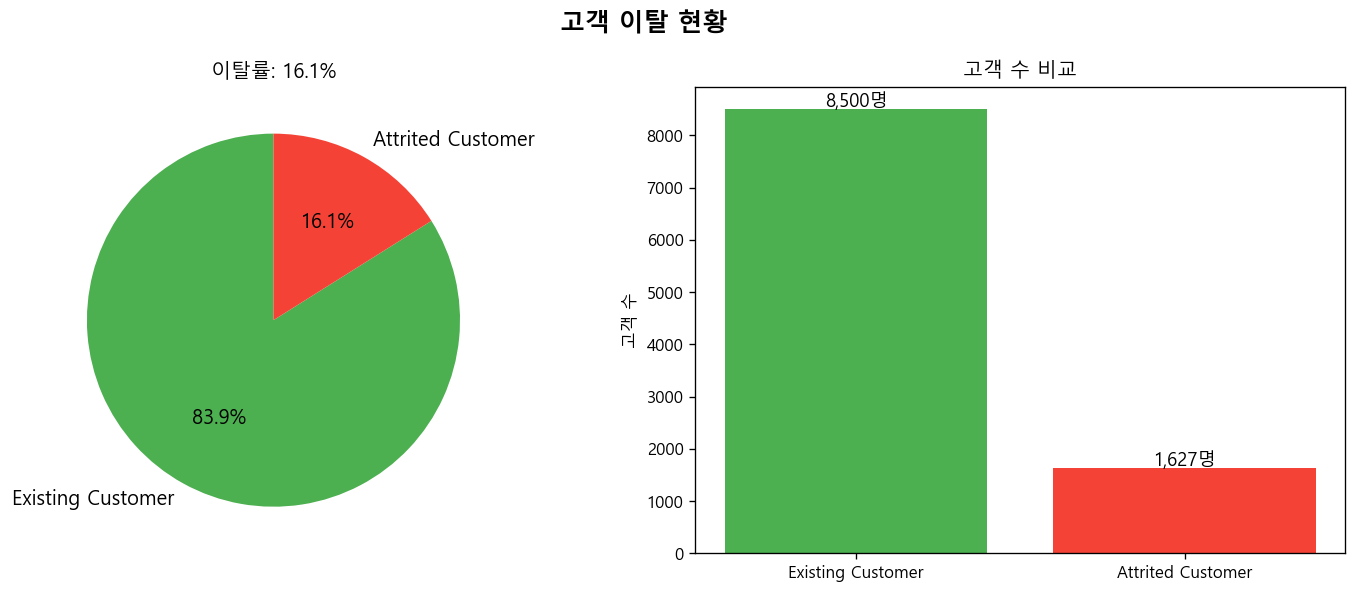


총 고객: 10,127명 | 이탈: 1,627명 | 유지: 8,500명


In [7]:
churn_counts = df['Attrition_Flag'].value_counts()
churn_rate   = df['Churned'].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('고객 이탈 현황', fontsize=15, fontweight='bold')

# 파이차트
colors = ['#4CAF50', '#F44336']
axes[0].pie(churn_counts, labels=churn_counts.index, autopct='%1.1f%%',
            colors=colors, startangle=90, textprops={'fontsize': 12})
axes[0].set_title(f'이탈률: {churn_rate:.1f}%')

# 바차트
axes[1].bar(churn_counts.index, churn_counts.values, color=colors)
for i, (label, val) in enumerate(zip(churn_counts.index, churn_counts.values)):
    axes[1].text(i, val + 50, f'{val:,}명', ha='center', fontsize=11)
axes[1].set_ylabel('고객 수')
axes[1].set_title('고객 수 비교')

plt.tight_layout()
plt.savefig('fig_01_churn_overview.png', bbox_inches='tight')
plt.show()
print(f'\n총 고객: {len(df):,}명 | 이탈: {churn_counts.get("Attrited Customer",0):,}명 | 유지: {churn_counts.get("Existing Customer",0):,}명')

## 2-3. 인구통계 분포 (연령, 성별, 소득, 교육수준)

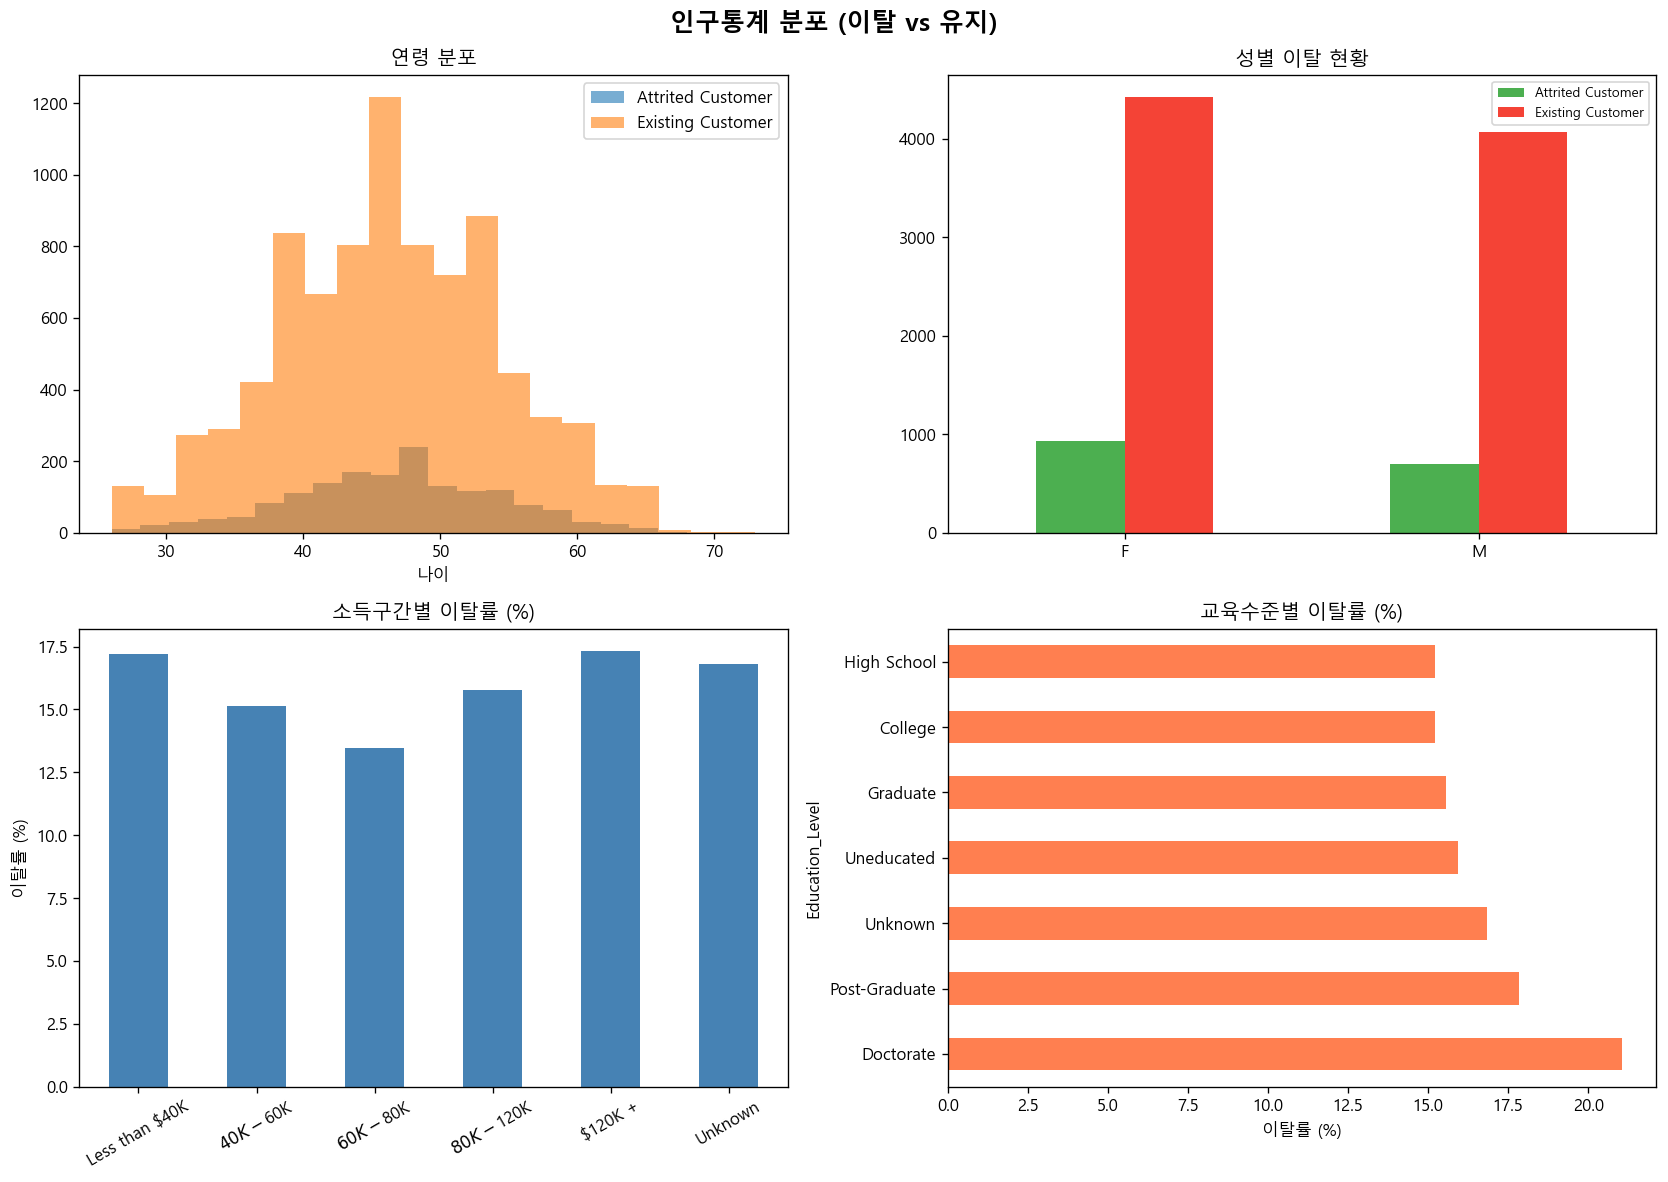

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('인구통계 분포 (이탈 vs 유지)', fontsize=15, fontweight='bold')

# 연령 분포
for flag, grp in df.groupby('Attrition_Flag'):
    axes[0,0].hist(grp['Customer_Age'], bins=20, alpha=0.6, label=flag)
axes[0,0].set_title('연령 분포')
axes[0,0].set_xlabel('나이')
axes[0,0].legend()

# 성별
gender_churn = df.groupby(['Gender', 'Attrition_Flag']).size().unstack()
gender_churn.plot(kind='bar', ax=axes[0,1], color=colors, rot=0)
axes[0,1].set_title('성별 이탈 현황')
axes[0,1].set_xlabel('')
axes[0,1].legend(fontsize=8)

# 소득구간
income_order = ['Less than $40K','$40K - $60K','$60K - $80K','$80K - $120K','$120K +','Unknown']
income_churn = df.groupby('Income_Category')['Churned'].mean().reindex(income_order) * 100
income_churn.plot(kind='bar', ax=axes[1,0], color='steelblue', rot=30)
axes[1,0].set_title('소득구간별 이탈률 (%)')
axes[1,0].set_ylabel('이탈률 (%)')
axes[1,0].set_xlabel('')

# 교육수준
edu_churn = df.groupby('Education_Level')['Churned'].mean().sort_values(ascending=False) * 100
edu_churn.plot(kind='barh', ax=axes[1,1], color='coral')
axes[1,1].set_title('교육수준별 이탈률 (%)')
axes[1,1].set_xlabel('이탈률 (%)')

plt.tight_layout()
plt.savefig('fig_02_demographics.png', bbox_inches='tight')
plt.show()

## 2-4. 카드 사용 행동 분포

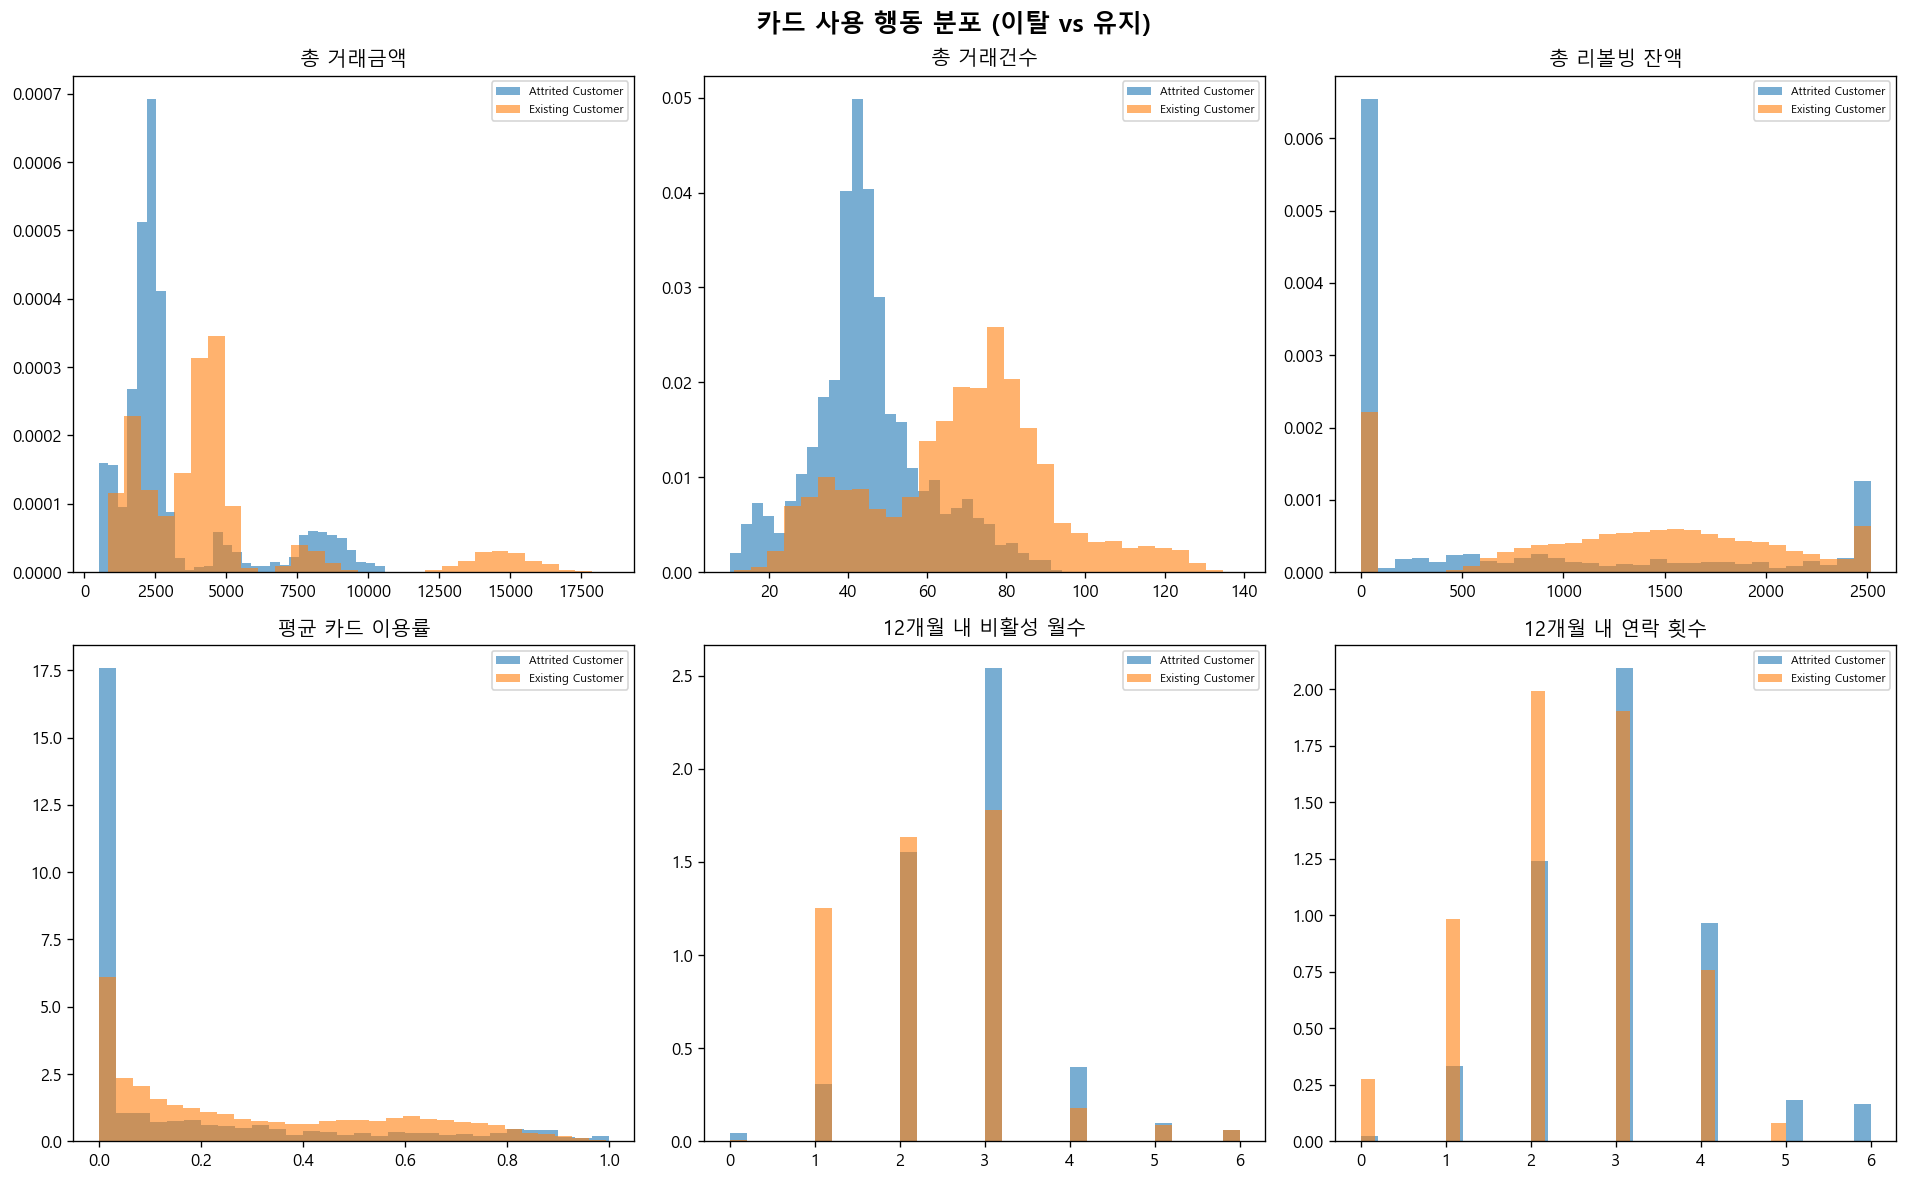

In [9]:
behavior_cols = ['Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Revolving_Bal',
                 'Avg_Utilization_Ratio', 'Months_Inactive_12_mon', 'Contacts_Count_12_mon']

col_labels = {
    'Total_Trans_Amt'       : '총 거래금액',
    'Total_Trans_Ct'        : '총 거래건수',
    'Total_Revolving_Bal'   : '총 리볼빙 잔액',
    'Avg_Utilization_Ratio' : '평균 카드 이용률',
    'Months_Inactive_12_mon': '12개월 내 비활성 월수',
    'Contacts_Count_12_mon' : '12개월 내 연락 횟수'
}

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('카드 사용 행동 분포 (이탈 vs 유지)', fontsize=15, fontweight='bold')

for ax, col in zip(axes.flatten(), behavior_cols):
    for flag, grp in df.groupby('Attrition_Flag'):
        ax.hist(grp[col], bins=30, alpha=0.6, label=flag, density=True)
    ax.set_title(col_labels[col])
    ax.legend(fontsize=7)

plt.tight_layout()
plt.savefig('fig_03_behavior.png', bbox_inches='tight')
plt.show()

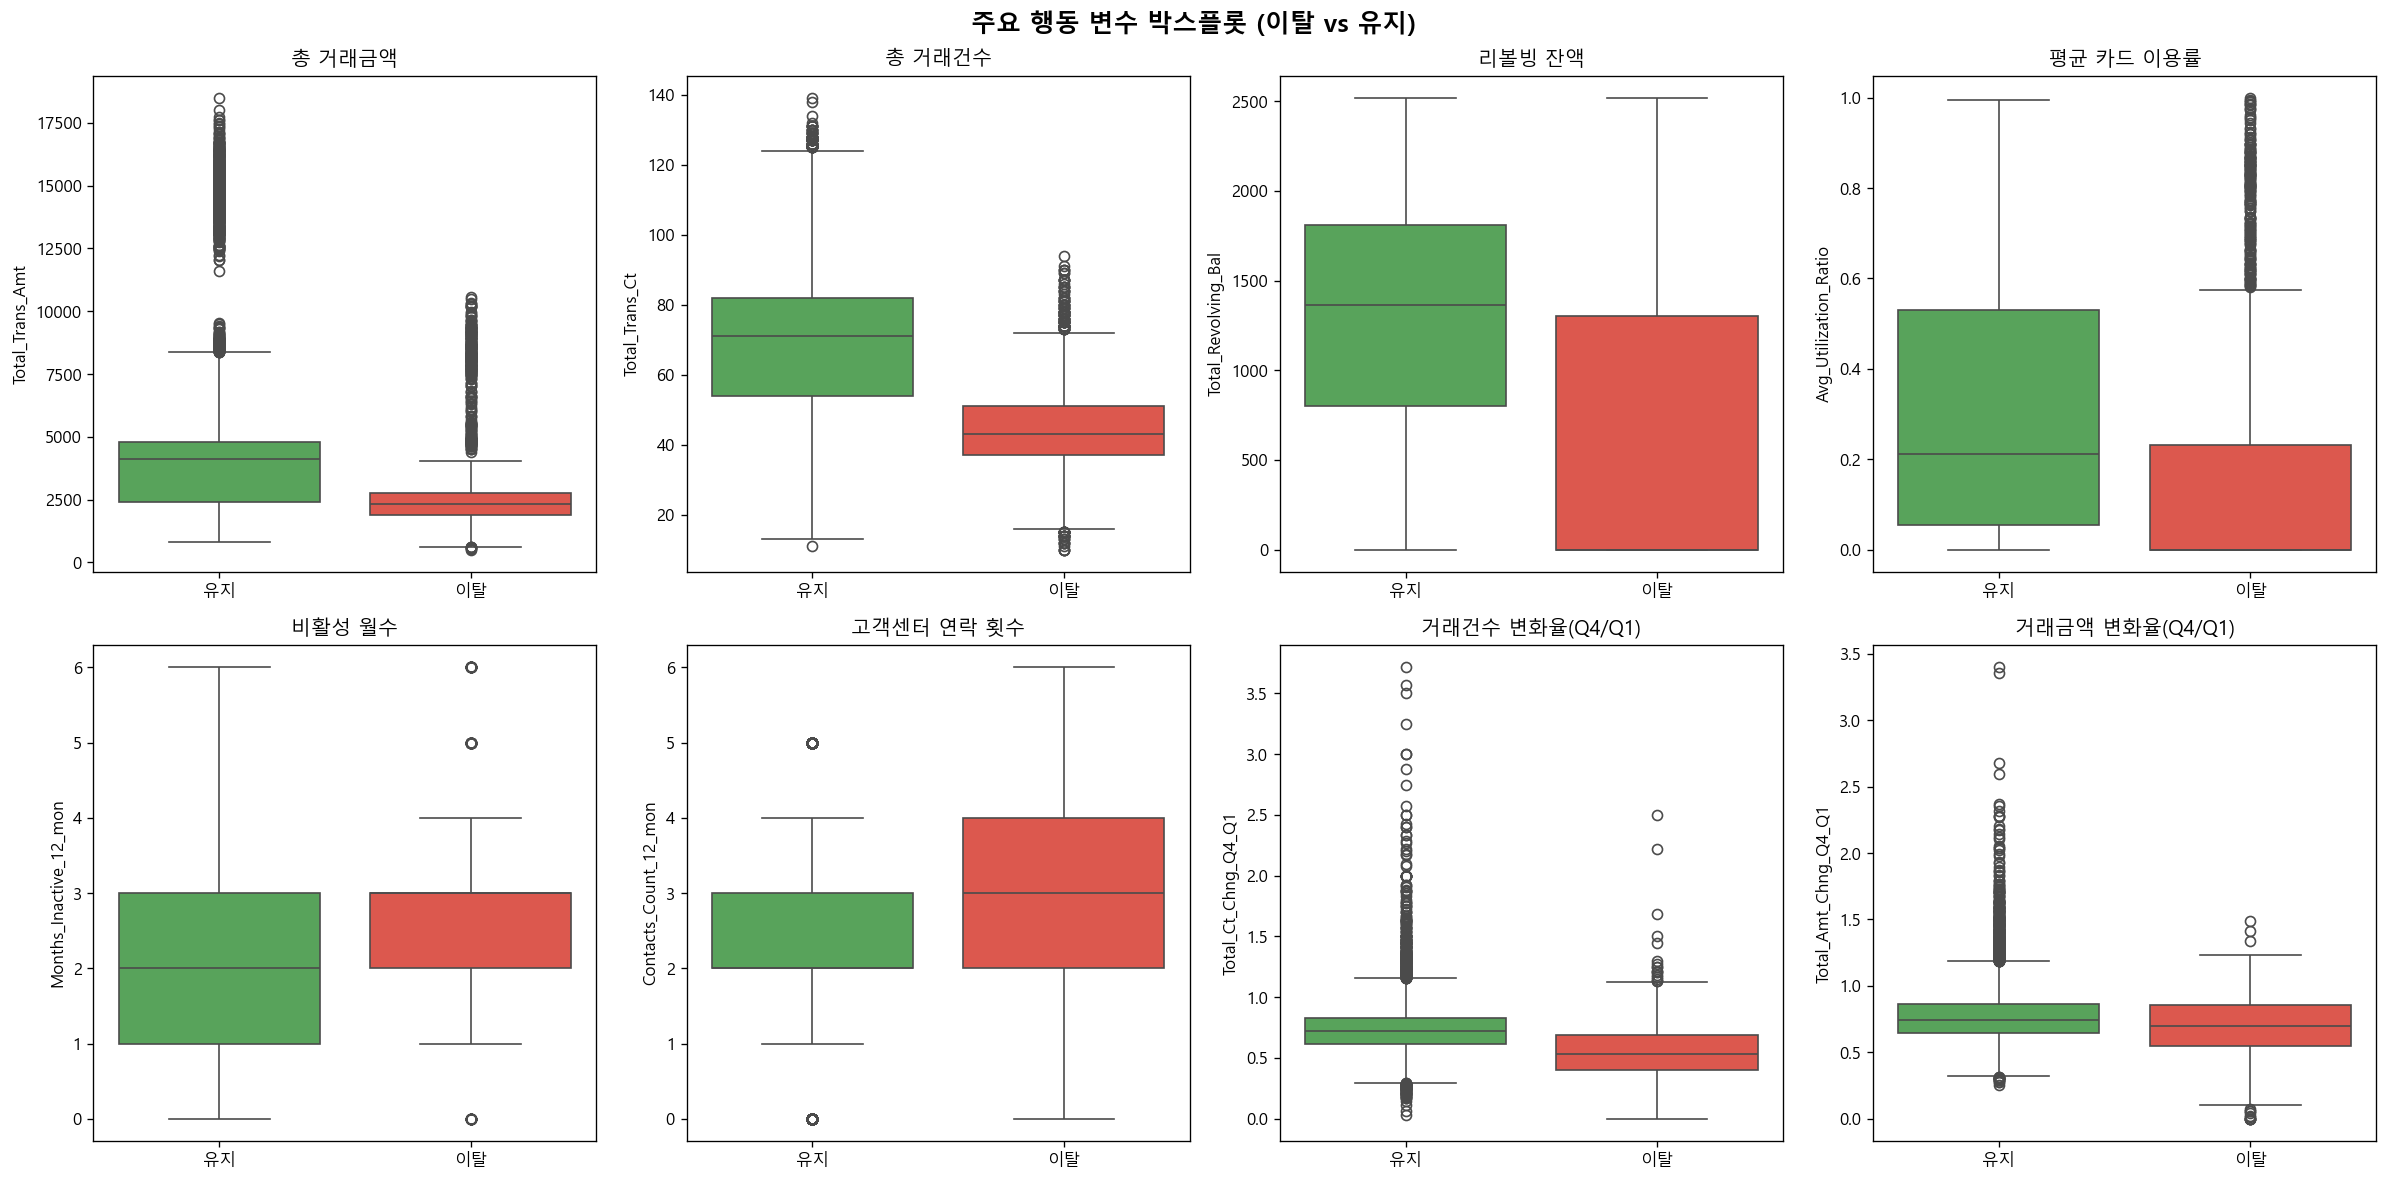

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib

matplotlib.rc('font', family='Malgun Gothic')
matplotlib.rc('axes', unicode_minus=False)
plt.rcParams['figure.dpi'] = 120

behavior_cols = [
    'Total_Trans_Amt', 'Total_Trans_Ct', 
    'Total_Revolving_Bal', 'Avg_Utilization_Ratio',
    'Months_Inactive_12_mon', 'Contacts_Count_12_mon',
    'Total_Ct_Chng_Q4_Q1', 'Total_Amt_Chng_Q4_Q1'
]

col_labels = {
    'Total_Trans_Amt'       : '총 거래금액',
    'Total_Trans_Ct'        : '총 거래건수',
    'Total_Revolving_Bal'   : '리볼빙 잔액',
    'Avg_Utilization_Ratio' : '평균 카드 이용률',
    'Months_Inactive_12_mon': '비활성 월수',
    'Contacts_Count_12_mon' : '고객센터 연락 횟수',
    'Total_Ct_Chng_Q4_Q1'   : '거래건수 변화율(Q4/Q1)',
    'Total_Amt_Chng_Q4_Q1'  : '거래금액 변화율(Q4/Q1)'
}

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
fig.suptitle('주요 행동 변수 박스플롯 (이탈 vs 유지)', fontsize=15, fontweight='bold')

for ax, col in zip(axes.flatten(), behavior_cols):
    sns.boxplot(data=df, x='Attrition_Flag', y=col,
                palette={'Existing Customer': '#4CAF50', 'Attrited Customer': '#F44336'},
                ax=ax)
    ax.set_title(col_labels[col])
    ax.set_xlabel('')
    ax.set_xticklabels(['유지', '이탈'])

plt.tight_layout()
plt.savefig('fig_boxplot_behavior.png', bbox_inches='tight')
plt.show()

## 2-5. 상관관계 히트맵

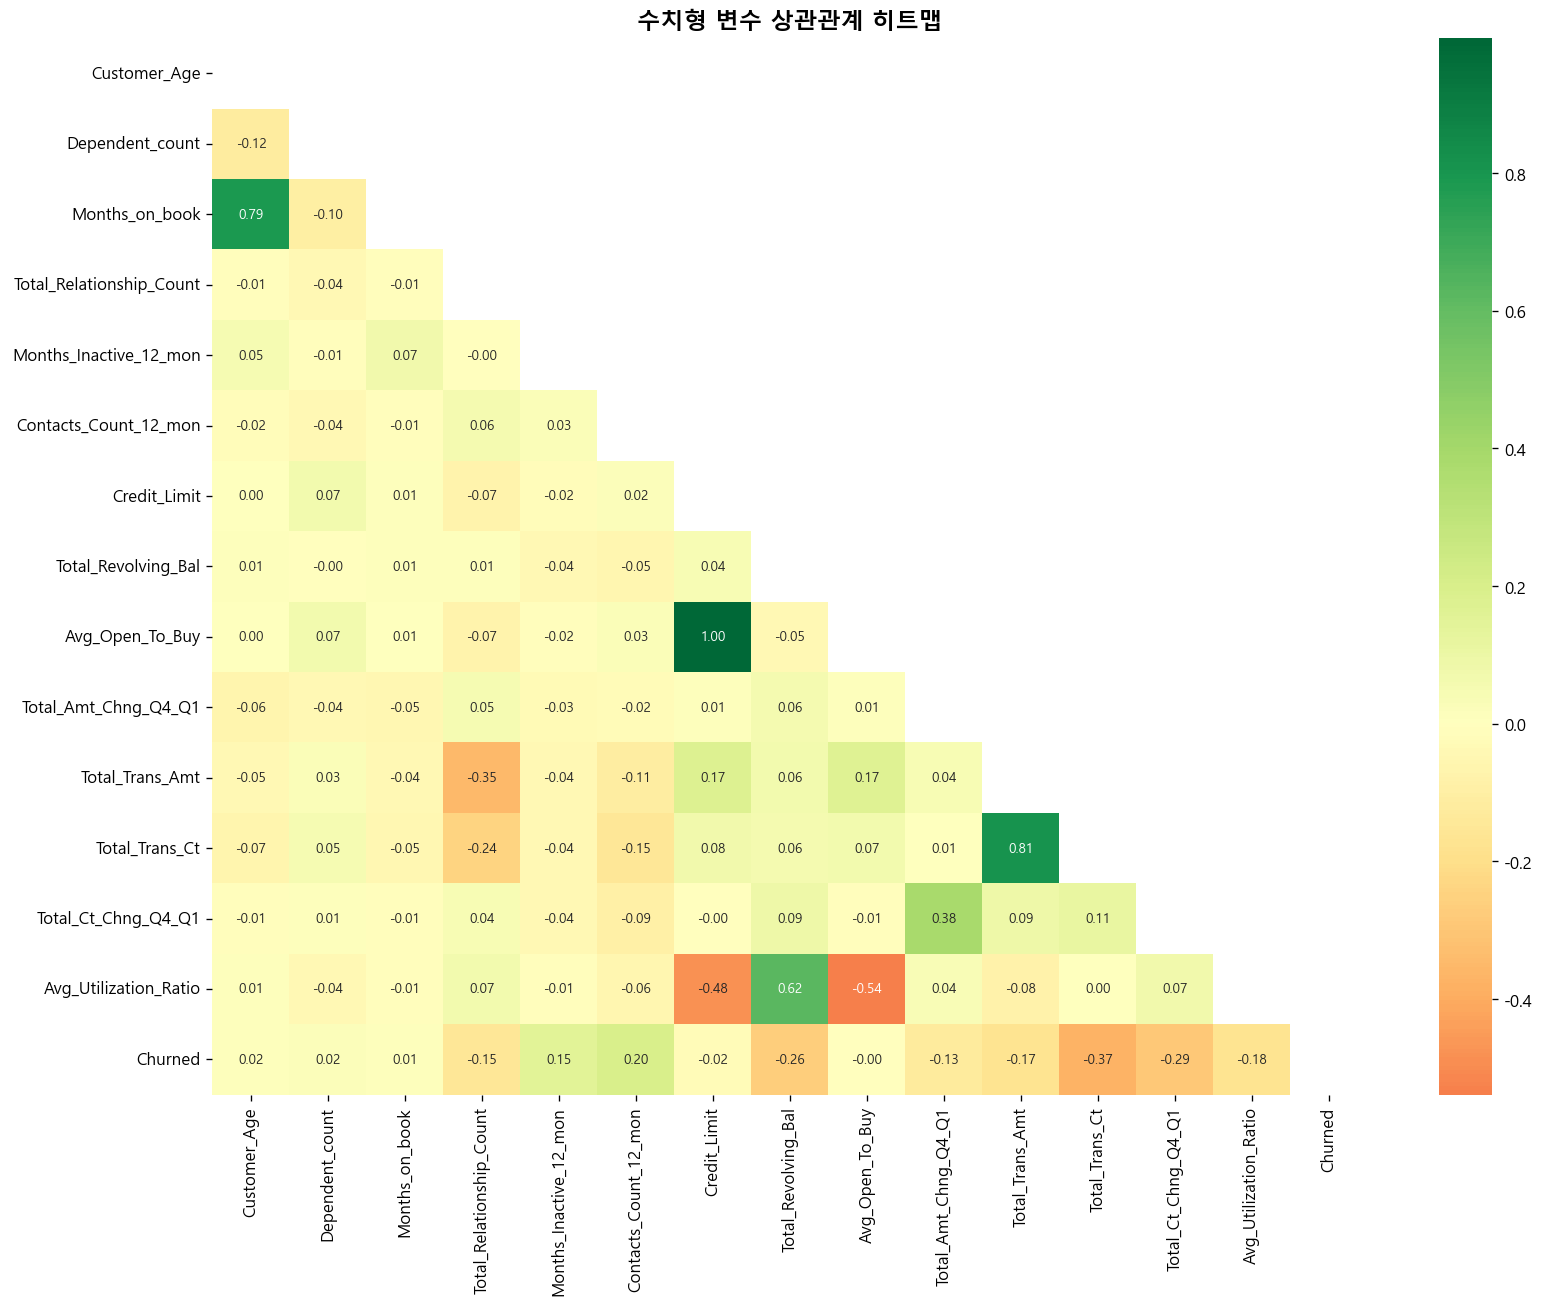

In [11]:
num_cols = df.select_dtypes(include=np.number).drop(columns=['CLIENTNUM']).columns
corr = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(14, 11))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdYlGn',
            center=0, ax=ax, annot_kws={'size': 8})
ax.set_title('수치형 변수 상관관계 히트맵', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('fig_04_correlation.png', bbox_inches='tight')
plt.show()

## 2-6. 이탈 고객 주요 특징 요약 (SQL 활용)

In [12]:
summary_sql = """
SELECT
    Attrition_Flag,
    COUNT(*)                        AS 고객수,
    ROUND(AVG(Customer_Age), 1)     AS 평균연령,
    ROUND(AVG(Credit_Limit), 0)     AS 평균신용한도,
    ROUND(AVG(Total_Trans_Amt), 0)  AS 평균거래금액,
    ROUND(AVG(Total_Trans_Ct), 1)   AS 평균거래건수,
    ROUND(AVG(Months_Inactive_12_mon), 2) AS 평균비활성월수,
    ROUND(AVG(Avg_Utilization_Ratio), 3)  AS 평균이용률
FROM customers
GROUP BY Attrition_Flag
"""
summary_df = pd.read_sql(summary_sql, con=engine)
display(summary_df)

,Attrition_Flag,고객수,평균연령,평균신용한도,평균거래금액,평균거래건수,평균비활성월수,평균이용률
0,Existing Customer,8500,46.3,8727.0,4655.0,68.7,2.27,0.296
1,Attrited Customer,1627,46.7,8136.0,3095.0,44.9,2.69,0.162


---
# 📊 STAGE 3: 이탈 예측 모델링

**분석 방법:** XGBoost + scale_pos_weight (클래스 가중치)

**선정 이유:**
- 이탈률 약 16% 수준은 SMOTE 등 오버샘플링 불필요 (데이터 왜곡 위험)
- 데이터를 건드리지 않고 가중치로 불균형 처리
- 트리 기반 앙상블로 비선형 관계 포착 및 변수 중요도(SHAP) 해석 용이

**모델 정의 및 한계:**
`Attrition_Flag` 를 라벨로 쓴 지도학습 이진 분류 모델, 즉 **이탈 예측 모델**이다.
단 데이터가 고객 1인당 1행으로 요약된 스냅샷이고 관측 기간과 예측 기간이 분리되지
않으므로 **이탈 시점과 리드타임은 예측하지 못한다.**

또한 이탈 고객의 낮은 거래량은 이탈의 *원인*이 아니라 이미 이탈이 진행된 *결과*일
수 있다. 즉 모델이 학습한 신호의 일부가 선행지표가 아닐 가능성이 있다.
따라서 산출물은 "언제 떠나는가"가 아니라 **접촉 우선순위 점수**로 사용한다.


In [13]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, ConfusionMatrixDisplay
from xgboost import XGBClassifier

# 피처 준비
cat_cols = ['Gender','Education_Level','Marital_Status','Income_Category',
            'Card_Category','Attrition_Flag']
# 분석 과정에서 df 에 추가된 파생 컬럼이 섞이지 않도록 명시적으로 제외한다.
_derived = [c for c in ['churn_prob', 'risk_tier', 'signal_count',
                        'trans_ct_decile'] if c in df.columns]
df_model = df.drop(columns=['CLIENTNUM'] + _derived).copy()
if _derived:
    print('제외한 파생 컬럼:', _derived)

# LabelEncoder 를 컬럼별로 따로 두고 인코딩 맵을 남긴다.
# 하나의 le 객체를 돌려 쓰면 학습 결과는 같지만 매핑이 보존되지 않아
# app.py 가 신규 고객을 스코어링할 때 같은 인코딩을 보장할 수 없다.
encoders  = {}
label_maps = {}
for col in cat_cols:
    if col in df_model.columns:
        enc = LabelEncoder()
        df_model[col] = enc.fit_transform(df_model[col].astype(str))
        encoders[col]   = enc
        label_maps[col] = {str(c): int(i) for i, c in enumerate(enc.classes_)}

print('=== 인코딩 맵 (추론 시 동일하게 적용해야 함) ===')
for col, m in label_maps.items():
    print(f'{col:20s} {m}')

X = df_model.drop(columns=['Churned','Attrition_Flag'])
y = df_model['Churned']

print(f'\n학습 피처 {X.shape[1]}개')
print(list(X.columns))

# SMOTE 없이 바로 분리
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f'\nTrain: {X_train.shape} | Test: {X_test.shape}')
print(f'이탈 비율 → Train: {y_train.mean():.2%} | Test: {y_test.mean():.2%}')


=== 인코딩 맵 (추론 시 동일하게 적용해야 함) ===
Gender               {'F': 0, 'M': 1}
Education_Level      {'College': 0, 'Doctorate': 1, 'Graduate': 2, 'High School': 3, 'Post-Graduate': 4, 'Uneducated': 5, 'Unknown': 6}
Marital_Status       {'Divorced': 0, 'Married': 1, 'Single': 2, 'Unknown': 3}
Income_Category      {'$120K +': 0, '$40K - $60K': 1, '$60K - $80K': 2, '$80K - $120K': 3, 'Less than $40K': 4, 'Unknown': 5}
Card_Category        {'Blue': 0, 'Gold': 1, 'Platinum': 2, 'Silver': 3}
Attrition_Flag       {'Attrited Customer': 0, 'Existing Customer': 1}

학습 피처 19개
['Customer_Age', 'Gender', 'Dependent_count', 'Education_Level', 'Marital_Status', 'Income_Category', 'Card_Category', 'Months_on_book', 'Total_Relationship_Count', 'Months_Inactive_12_mon', 'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal', 'Avg_Open_To_Buy', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio']

Train: (8101, 19) | Test: (2026, 19)
이탈 비율 → Train: 

In [14]:
# 모델 학습
model = XGBClassifier(
    n_estimators=300, max_depth=6, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=(y_train==0).sum() / (y_train==1).sum(),  # class_weight 대신
    eval_metric='logloss', random_state=42
)
model.fit(X_train, y_train,
          eval_set=[(X_test, y_test)], verbose=False)

y_pred  = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]
auc     = roc_auc_score(y_test, y_proba)

print(f'\nROC-AUC: {auc:.4f}')
print('\n분류 리포트:')
print(classification_report(y_test, y_pred, target_names=['유지','이탈']))


ROC-AUC: 0.9930

분류 리포트:
              precision    recall  f1-score   support

          유지       0.98      0.98      0.98      1701
          이탈       0.90      0.90      0.90       325

    accuracy                           0.97      2026
   macro avg       0.94      0.94      0.94      2026
weighted avg       0.97      0.97      0.97      2026



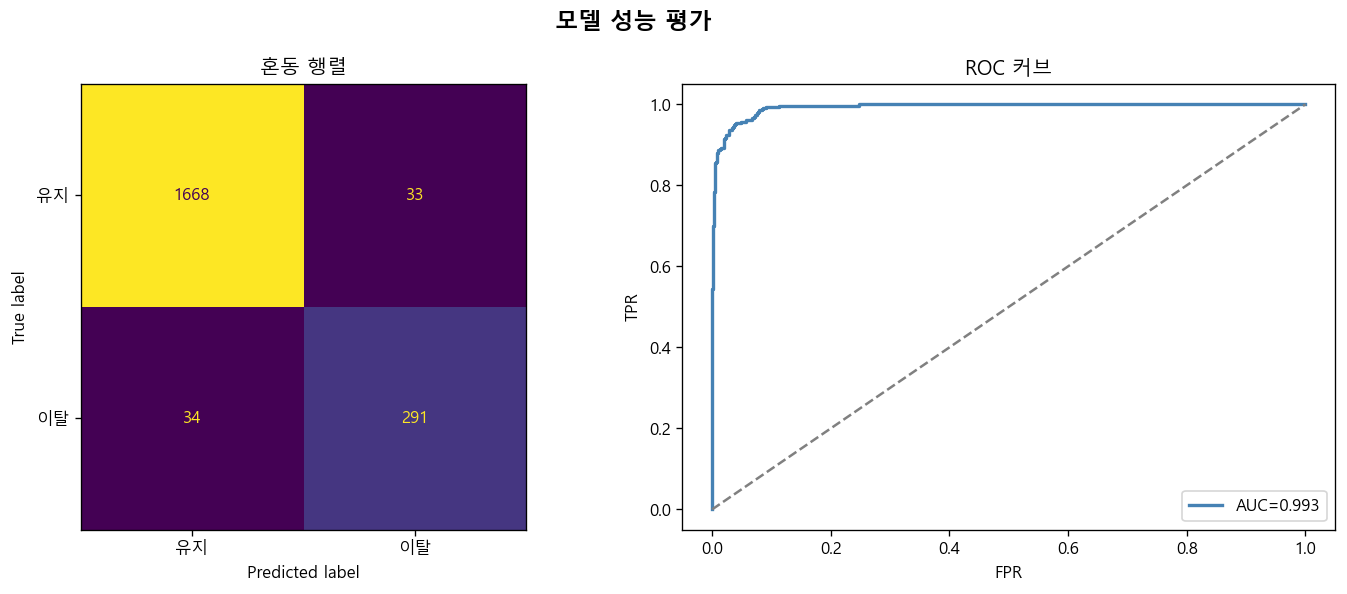

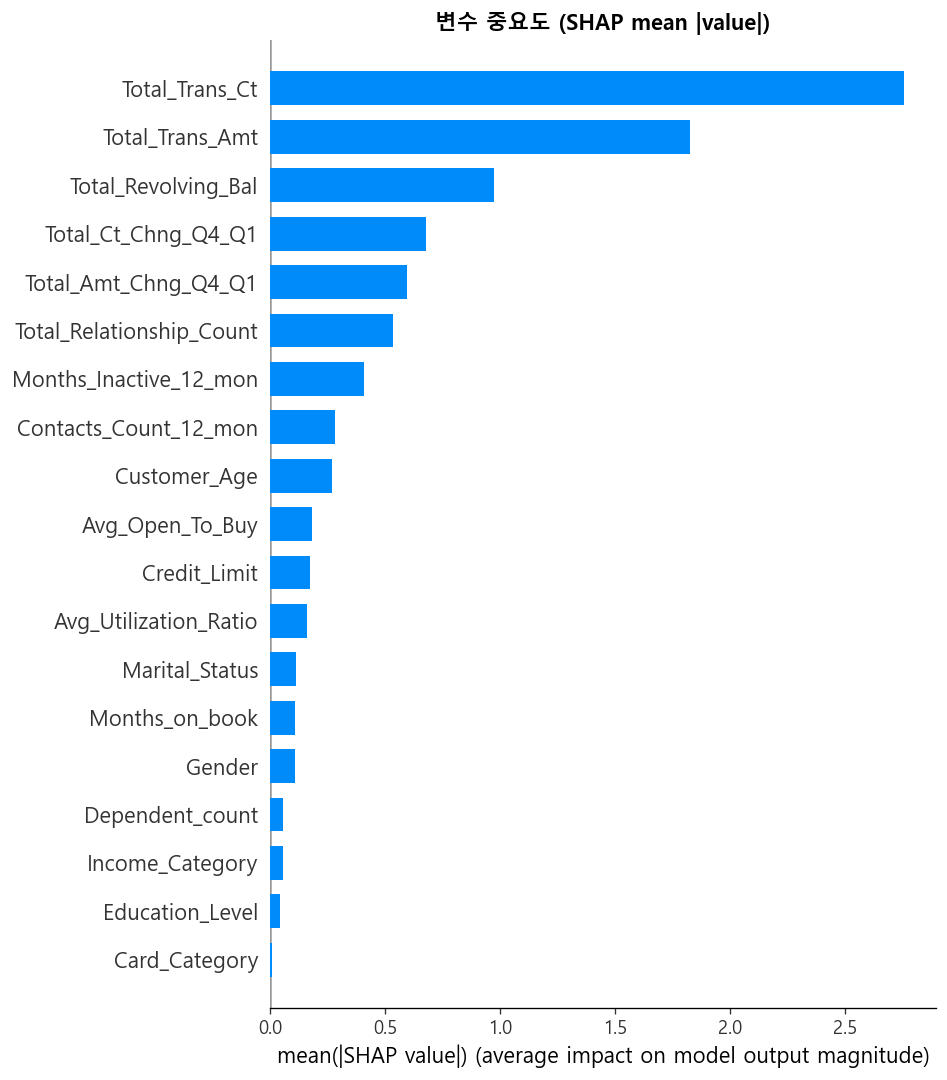

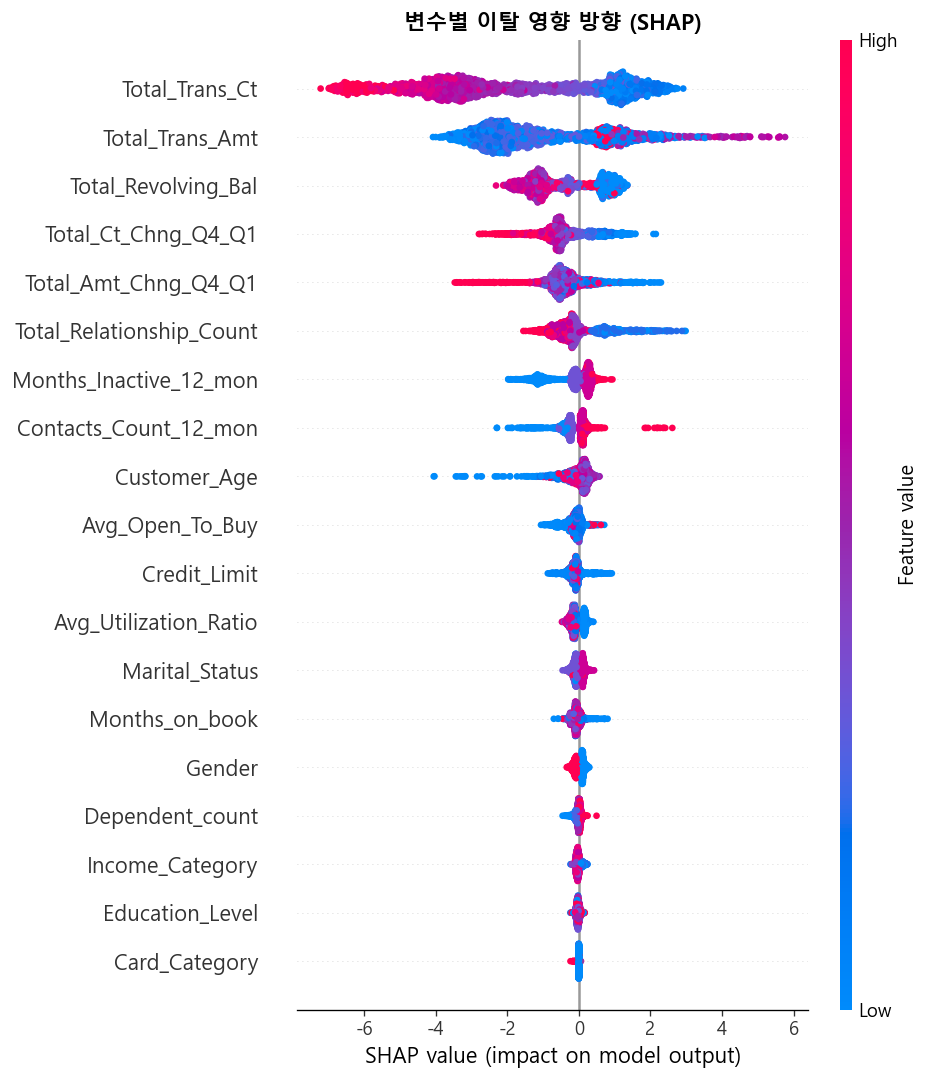

In [15]:
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, ConfusionMatrixDisplay
import shap

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('모델 성능 평가', fontsize=14, fontweight='bold')

# 혼동 행렬
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                        display_labels=['유지','이탈']).plot(ax=axes[0], colorbar=False)
axes[0].set_title('혼동 행렬')

# ROC 커브
fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, label=f'AUC={auc:.3f}', color='steelblue', lw=2)
axes[1].plot([0,1],[0,1],'--', color='gray')
axes[1].set_xlabel('FPR'); axes[1].set_ylabel('TPR')
axes[1].set_title('ROC 커브'); axes[1].legend()

plt.tight_layout()
plt.savefig('fig_05_model_eval.png', bbox_inches='tight')
plt.show()

# SHAP 변수 중요도
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

# 1. 변수 중요도 bar
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, plot_type='bar', show=False)
plt.title('변수 중요도 (SHAP mean |value|)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fig_shap_bar.png', bbox_inches='tight')
plt.show()

# 2. 방향 포함 summary plot
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_test, show=False)
plt.title('변수별 이탈 영향 방향 (SHAP)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fig_shap_direction.png', bbox_inches='tight')
plt.show()

## 📊 모델 성능 해석

### 혼동 행렬 (Confusion Matrix)
- **TP (이탈 → 이탈 예측):** 291명 → 실제 이탈 고객 중 정확히 잡아낸 수
- **TN (유지 → 유지 예측):** 1,668명 → 실제 유지 고객 중 정확히 잡아낸 수
- **FP (유지 → 이탈 예측):** 33명 → 실제 유지인데 이탈로 잘못 예측 (불필요한 마케팅 비용 발생)
- **FN (이탈 → 유지 예측):** 34명 → 실제 이탈인데 놓친 고객 **(가장 위험, 그냥 떠나보내는 케이스)**

### ROC-AUC: 0.993
- 홀드아웃(2,026명) 기준. 이탈 Precision 0.90 / Recall 0.90
- 실제 이탈 고객 325명 중 **291명(89.5%) 사전 식별**
- 놓친 34명은 임계값을 낮춰 줄일 수 있으나 FP(불필요한 마케팅 비용)가 늘어난다

### SHAP 변수 중요도

| 변수 | 위치 | 해석 |
|------|------|------|
| `Total_Trans_Ct` 거래건수 | 중요도 1위 | 방향은 아래 "십분위 점검"에서 확인 — 단조 감소 관계가 아니다 |
| `Total_Trans_Amt` 거래금액 | 2위 | 거래건수와 함께 카드 활성도를 나타내는 지표 |
| `Total_Revolving_Bal` 리볼빙 잔액 | 3위 | 단순 상관은 -0.02로 거의 0. 비선형·상호작용으로 작동하며 **방향 해석이 어렵다** |
| `Total_Ct_Chng_Q4_Q1` 건수 변화율 | 상위 | 이탈과 상관 -0.37로 단일 신호 중 가장 강함. 직전 분기 대비 감소한 고객이 위험 |
| `Contacts_Count_12_mon` 연락 횟수 | 상위 | 많을수록 이탈 ↑. 불만 누적 신호로 해석 |
| `Total_Relationship_Count` 보유 상품 수 | 상위 | 많을수록 이탈 ↓. 관계 깊이가 이탈 방어 |
| 인구통계 (나이·성별·소득) | 하위권 | 이탈은 속성이 아니라 사용 패턴이 결정 |

> **주의:** SHAP 중요도는 "얼마나 많이 쓰이는가"를 말하고 **"어느 방향인가"를 말하지 않는다.**
> 거래건수가 중요도 1위라는 사실만으로 "적을수록 위험"이라고 읽으면 안 되고,
> 실제 분포에서 확인해야 한다. 다음 셀이 그 점검이다.

### 결론
> 이탈은 인구통계가 아닌 **행동 패턴**이 결정한다.
> 거래건수/금액 감소 + 고객센터 연락 증가가 복합적으로 나타날 때 위험이 가장 높다.
> 단일 변수가 아닌 **복합 패턴**으로 포착하는 것이 핵심이다.


## 3-1. 십분위 점검 — "적을수록 이탈"이 맞는가

SHAP 중요도 1위가 거래건수이므로 "거래가 적을수록 이탈"로 읽기 쉽다.
그러나 중요도는 방향을 말하지 않으므로, 거래건수를 십분위로 끊어
**구간별 실제 이탈률**을 직접 확인한다.


,최소거래건수,최대거래건수,고객수,이탈고객수,이탈률
Total_Trans_Ct,,,,,
1,10,33,1018,271,26.6
2,34,41,1058,407,38.5
3,42,50,1052,509,48.4
4,51,61,1037,217,20.9
5,62,67,958,78,8.1
6,68,73,1119,60,5.4
7,74,78,978,44,4.5
8,79,83,936,20,2.1
9,84,92,983,20,2.0


이탈률 정점 구간: 3분위 (42~50건), 48.4%
최하위 1분위 (10~33건): 26.6%

→ 단조 관계가 아니다. 거래가 가장 적은 층이 가장 위험하지 않다.
  거래가 아주 적은 고객은 애초에 카드를 쓰지 않는 집단이므로
  이탈 신호로 보기 어렵다. 위험한 쪽은 "쓰다가 줄어든" 경우다.


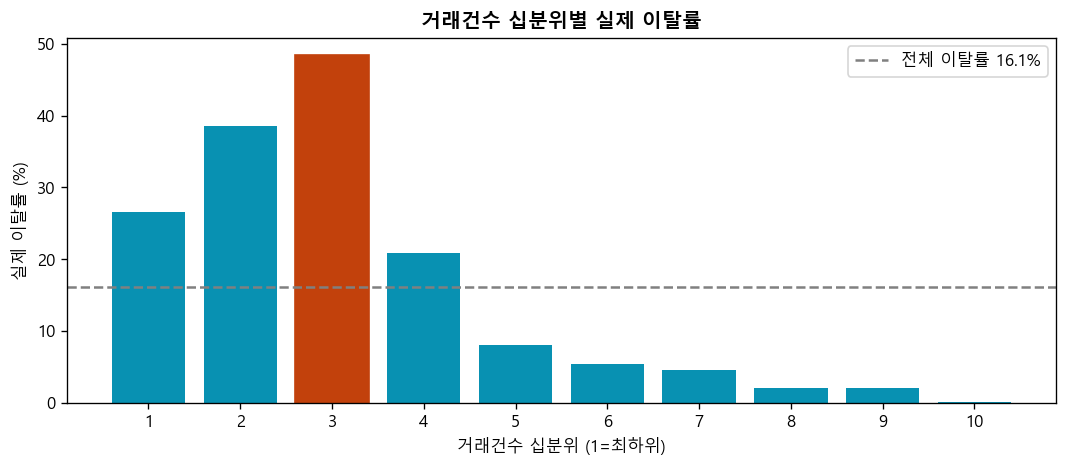

In [16]:
# ── 거래건수 십분위별 실제 이탈률 ──────────────────────────────────
# 단조 감소 관계인지(적을수록 이탈률이 높은지) 분포에서 직접 확인한다.
# df 에 컬럼을 추가하지 않는다. 재실행 순서에 따라 학습 피처로 섞일 수 있다.
_decile_key = pd.qcut(df['Total_Trans_Ct'], q=10,
                      labels=False, duplicates='drop') + 1

decile = df.groupby(_decile_key).agg(
    최소거래건수=('Total_Trans_Ct', 'min'),
    최대거래건수=('Total_Trans_Ct', 'max'),
    고객수=('CLIENTNUM', 'count'),
    이탈고객수=('Churned', 'sum'),
    이탈률=('Churned', 'mean'),
)
decile['이탈률'] = (decile['이탈률'] * 100).round(1)   # 반올림은 % 변환 뒤에
display(decile)

peak = decile['이탈률'].idxmax()
print(f"이탈률 정점 구간: {peak}분위 "
      f"({decile.loc[peak, '최소거래건수']}~{decile.loc[peak, '최대거래건수']}건), "
      f"{decile.loc[peak, '이탈률']}%")
print(f"최하위 1분위 ({decile.loc[1, '최소거래건수']}~{decile.loc[1, '최대거래건수']}건): "
      f"{decile.loc[1, '이탈률']}%")
print()
if peak > 1:
    print('→ 단조 관계가 아니다. 거래가 가장 적은 층이 가장 위험하지 않다.')
    print('  거래가 아주 적은 고객은 애초에 카드를 쓰지 않는 집단이므로')
    print('  이탈 신호로 보기 어렵다. 위험한 쪽은 "쓰다가 줄어든" 경우다.')
else:
    print('→ 최하위 구간이 정점이다. 단조 관계로 읽어도 무리가 없다.')

plt.figure(figsize=(9, 4))
bars = plt.bar(decile.index.astype(str), decile['이탈률'], color='#0891B2')
bars[list(decile.index).index(peak)].set_color('#C2410C')
plt.axhline(df['Churned'].mean() * 100, ls='--', color='gray',
            label=f"전체 이탈률 {df['Churned'].mean()*100:.1f}%")
plt.xlabel('거래건수 십분위 (1=최하위)')
plt.ylabel('실제 이탈률 (%)')
plt.title('거래건수 십분위별 실제 이탈률', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.savefig('fig_decile_trans_ct.png', bbox_inches='tight')
plt.show()


## 3-2. 위험 신호 임계값의 근거 — 사분위 경계

고위험 판정에 쓰는 임계값을 직관으로 정하지 않기 위해,
각 변수의 **사분위 경계**를 기준으로 삼는다. 아래 셀이 그 근거다.


In [17]:
# ── 룰 임계값의 근거: 각 변수의 사분위 경계 ────────────────────────
signal_cols = {
    'Total_Trans_Ct'          : ('거래건수',        '하위 25%'),
    'Total_Ct_Chng_Q4_Q1'     : ('거래건수 변화율', '하위 25%'),
    'Contacts_Count_12_mon'   : ('고객센터 연락',   '상위 25%'),
    'Total_Relationship_Count': ('보유 상품 수',    '하위 25%'),
}

rows = []
for col, (label, side) in signal_cols.items():
    q25, q50, q75 = df[col].quantile([.25, .50, .75])
    churn_mean = df.loc[df['Churned'] == 1, col].mean()
    keep_mean  = df.loc[df['Churned'] == 0, col].mean()
    rows.append({
        '변수': label, '컬럼': col, '위험 방향': side,
        '25%': round(q25, 3), '중앙': round(q50, 3), '75%': round(q75, 3),
        '유지 평균': round(keep_mean, 2), '이탈 평균': round(churn_mean, 2),
    })

display(pd.DataFrame(rows).set_index('변수'))

print('임계값은 위 사분위 경계에서 가져온다 (하위 25% 또는 상위 25%).')
print('이탈 평균과도 같은 방향이라 두 근거가 일치한다.')


,컬럼,위험 방향,25%,중앙,75%,유지 평균,이탈 평균
변수,,,,,,,
거래건수,Total_Trans_Ct,하위 25%,45.000,67.000,81.000,68.67,44.93
거래건수 변화율,Total_Ct_Chng_Q4_Q1,하위 25%,0.582,0.702,0.818,0.74,0.55
고객센터 연락,Contacts_Count_12_mon,상위 25%,2.000,2.000,3.000,2.36,2.97
보유 상품 수,Total_Relationship_Count,하위 25%,3.000,4.000,5.000,3.91,3.28


임계값은 위 사분위 경계에서 가져온다 (하위 25% 또는 상위 25%).
이탈 평균과도 같은 방향이라 두 근거가 일치한다.


---
# 📈 STAGE 4: 고위험 유지 고객 특성 분석 및 전략 도출

**목적:** 이탈 패턴 유사도 모델로 식별된 고위험 유지 고객을 대상으로
인구통계 및 금융 행동 특성을 안전군과 비교 분석하여 이탈 원인을 추정하고 맞춤 전략을 제시

**분석 순서:**
1. 전체 고객 이탈 확률 스코어링 → 5분위 세분화
2. 고위험군(매우높음) 중 유지 고객 추출
3. 안전군(매우낮음)과 특성 비교
4. 원인 추정 및 맞춤 전략 도출
5. 기대효과 수치화

In [25]:
# ── 전체 고객 이탈 확률 스코어링 → 5분위 등급 ──────────────────────
# 주의: 아래는 학습 데이터를 포함한 전체 in-sample 스코어링이다.
# 등급별 실제 이탈률이 낙관적으로 나올 수 있다는 점을 전제로 읽어야 한다.
X_orig = df_model.drop(columns=['Churned', 'Attrition_Flag'])
df['churn_prob'] = model.predict_proba(X_orig)[:, 1]

# 등급은 확률의 5분위로 끊는다 (고정 임계값이 아님).
# 각 등급 인원이 거의 같아 "상위 20% 접촉" 식의 예산 설계가 가능하다.
df['risk_tier'] = pd.qcut(df['churn_prob'], q=5,
                          labels=['매우낮음', '낮음', '보통', '높음', '매우높음'])

# 등급 경계값을 함께 남긴다 (run 간 비교 및 이력 추적용)
cuts = df.groupby('risk_tier', observed=True)['churn_prob'].agg(['min', 'max']).round(4)
cuts.columns = ['확률_하한', '확률_상한']

risk_summary = df.groupby('risk_tier', observed=True).agg(
    고객수=('CLIENTNUM', 'count'),
    이탈고객수=('Churned', 'sum'),
    실제이탈률=('Churned', 'mean'),
    평균거래건수=('Total_Trans_Ct', 'mean'),
    평균거래금액=('Total_Trans_Amt', 'mean'),
    평균리볼빙잔액=('Total_Revolving_Bal', 'mean'),
    평균연락횟수=('Contacts_Count_12_mon', 'mean'),
    평균비활성월수=('Months_Inactive_12_mon', 'mean'),
)

# ⚠️ 반올림은 반드시 % 변환 뒤에 한다.
#    비율 상태에서 .round(2) 를 걸면 0.0044 -> 0.0 이 되어 0.4% 가 0.0% 로 찍힌다.
risk_summary['실제이탈률'] = (risk_summary['실제이탈률'] * 100).round(1)
for c in ['평균거래건수', '평균거래금액', '평균리볼빙잔액', '평균연락횟수', '평균비활성월수']:
    risk_summary[c] = risk_summary[c].round(2)

display(risk_summary.join(cuts))

print('실제이탈률이 등급 순서대로 단조 증가해야 이 점수를 신뢰할 수 있다.')
print('단조성이 깨지면 재학습 신호로 본다.')


,고객수,이탈고객수,실제이탈률,평균거래건수,평균거래금액,평균리볼빙잔액,평균연락횟수,평균비활성월수,확률_하한,확률_상한
risk_tier,,,,,,,,,,
매우낮음,2026,0,0.0,76.46,4595.24,1395.93,2.07,1.94,0.0000,0.0003
낮음,2025,0,0.0,75.79,5382.55,1248.67,2.27,2.31,0.0003,0.0009
보통,2025,0,0.0,70.53,5410.36,1255.83,2.44,2.41,0.0009,0.0034
높음,2025,9,0.4,56.25,3639.63,1190.28,2.55,2.39,0.0034,0.0922
매우높음,2026,1618,79.9,45.26,2993.25,723.46,2.94,2.66,0.0927,0.9999


실제이탈률이 등급 순서대로 단조 증가해야 이 점수를 신뢰할 수 있다.
단조성이 깨지면 재학습 신호로 본다.


In [26]:
signal_count = (
      (df['Total_Trans_Ct']           < 45 ).astype(int)
    + (df['Total_Ct_Chng_Q4_Q1']      < 0.6).astype(int)
    + (df['Contacts_Count_12_mon']   >= 3  ).astype(int)
    + (df['Total_Relationship_Count'] <= 3  ).astype(int)
)

base_rate   = df['Churned'].mean()
total_churn = df['Churned'].sum()

scorecard = df.groupby(signal_count).agg(
    고객수=('CLIENTNUM', 'count'),
    이탈고객수=('Churned', 'sum'),
    이탈률=('Churned', 'mean'),
)
scorecard['리프트'] = (scorecard['이탈률'] / base_rate).round(2)
scorecard['이탈률'] = (scorecard['이탈률'] * 100).round(1)
scorecard['포착률'] = (scorecard['이탈고객수'] / total_churn * 100).round(1)
scorecard.index.name = '이탈신호_개수'
display(scorecard)

rule_top  = df[signal_count == 4]
model_top = df[df['risk_tier'] == '매우높음']

compare = pd.DataFrame([
    {'방식': '룰 (신호 4개)', '대상 고객수': len(rule_top),
     '대상군 이탈률(%)': round(rule_top['Churned'].mean() * 100, 1),
     '포착률(%)': round(rule_top['Churned'].sum() / total_churn * 100, 1)},
    {'방식': '모델 (매우높음)', '대상 고객수': len(model_top),
     '대상군 이탈률(%)': round(model_top['Churned'].mean() * 100, 1),
     '포착률(%)': round(model_top['Churned'].sum() / total_churn * 100, 1)},
])
display(compare)

print(f"정밀도: 룰 {rule_top['Churned'].mean():.1%} vs 모델 {model_top['Churned'].mean():.1%}")
print(f"포착률: 룰 {rule_top['Churned'].sum()/total_churn:.1%} vs 모델 {model_top['Churned'].sum()/total_churn:.1%}")

,고객수,이탈고객수,이탈률,리프트,포착률
이탈신호_개수,,,,,
0,1691,44,2.6,0.16,2.7
1,4039,284,7.0,0.44,17.5
2,2865,491,17.1,1.07,30.2
3,1147,497,43.3,2.70,30.5
4,385,311,80.8,5.03,19.1


,방식,대상 고객수,대상군 이탈률(%),포착률(%)
0,룰 (신호 4개),385,80.8,19.1
1,모델 (매우높음),2026,79.9,99.4


정밀도: 룰 80.8% vs 모델 79.9%
포착률: 룰 19.1% vs 모델 99.4%


In [19]:
# 기대효과 수치화를 위한 기준값 산출
print('=== 전체 고객 기준 ===')
print(f'전체 고객 수: {len(df):,}명')
print(f'전체 이탈 고객 수: {df["Churned"].sum():,}명')
print(f'전체 이탈률: {df["Churned"].mean():.1%}')

print('\n=== 위험도별 고객 수 ===')
print(df.groupby("risk_tier", observed=True)["Churned"].agg(["count", "sum", "mean"]).round(4))

print('\n=== 매우높음 그룹 ===')
df_high = df[df['risk_tier'] == '매우높음'].copy()
df_high_existing = df_high[df_high['Attrition_Flag'] == 'Existing Customer']
print(f'매우높음 전체        : {len(df_high):,}명')
print(f'  이미 이탈한 고객   : {df_high["Churned"].sum():,}명')
print(f'  아직 유지 중인 고객: {len(df_high_existing):,}명  ← 개입 대상')

# ⚠️ 아래 두 평균을 혼동하면 안 된다.
#    개입 대상의 가치는 '유지 중인 고객'의 평균이어야 한다.
#    전체 평균에는 이미 떠난 고객의 거래액이 섞여 있어 규모가 부풀려진다.
print()
print(f'평균 거래금액 (매우높음 전체, 이탈자 포함): '
      f'${df_high["Total_Trans_Amt"].mean():,.0f}   ← 기대효과 계산에 쓰지 말 것')
print(f'평균 거래금액 (유지 중인 개입 대상만)     : '
      f'${df_high_existing["Total_Trans_Amt"].mean():,.0f}   ← 이 값을 쓴다')
print(f'평균 거래건수 (매우높음 전체)             : {df_high["Total_Trans_Ct"].mean():.1f}건')


=== 전체 고객 기준 ===
전체 고객 수: 10,127명
전체 이탈 고객 수: 1,627명
전체 이탈률: 16.1%

=== 위험도별 고객 수 ===
           count   sum    mean
risk_tier                     
매우낮음        2026     0  0.0000
낮음          2025     0  0.0000
보통          2025     0  0.0000
높음          2025     9  0.0044
매우높음        2026  1618  0.7986

=== 매우높음 그룹 ===
매우높음 전체        : 2,026명
  이미 이탈한 고객   : 1,618명
  아직 유지 중인 고객: 408명  ← 개입 대상

평균 거래금액 (매우높음 전체, 이탈자 포함): $2,993   ← 기대효과 계산에 쓰지 말 것
평균 거래금액 (유지 중인 개입 대상만)     : $2,594   ← 이 값을 쓴다
평균 거래건수 (매우높음 전체)             : 45.3건


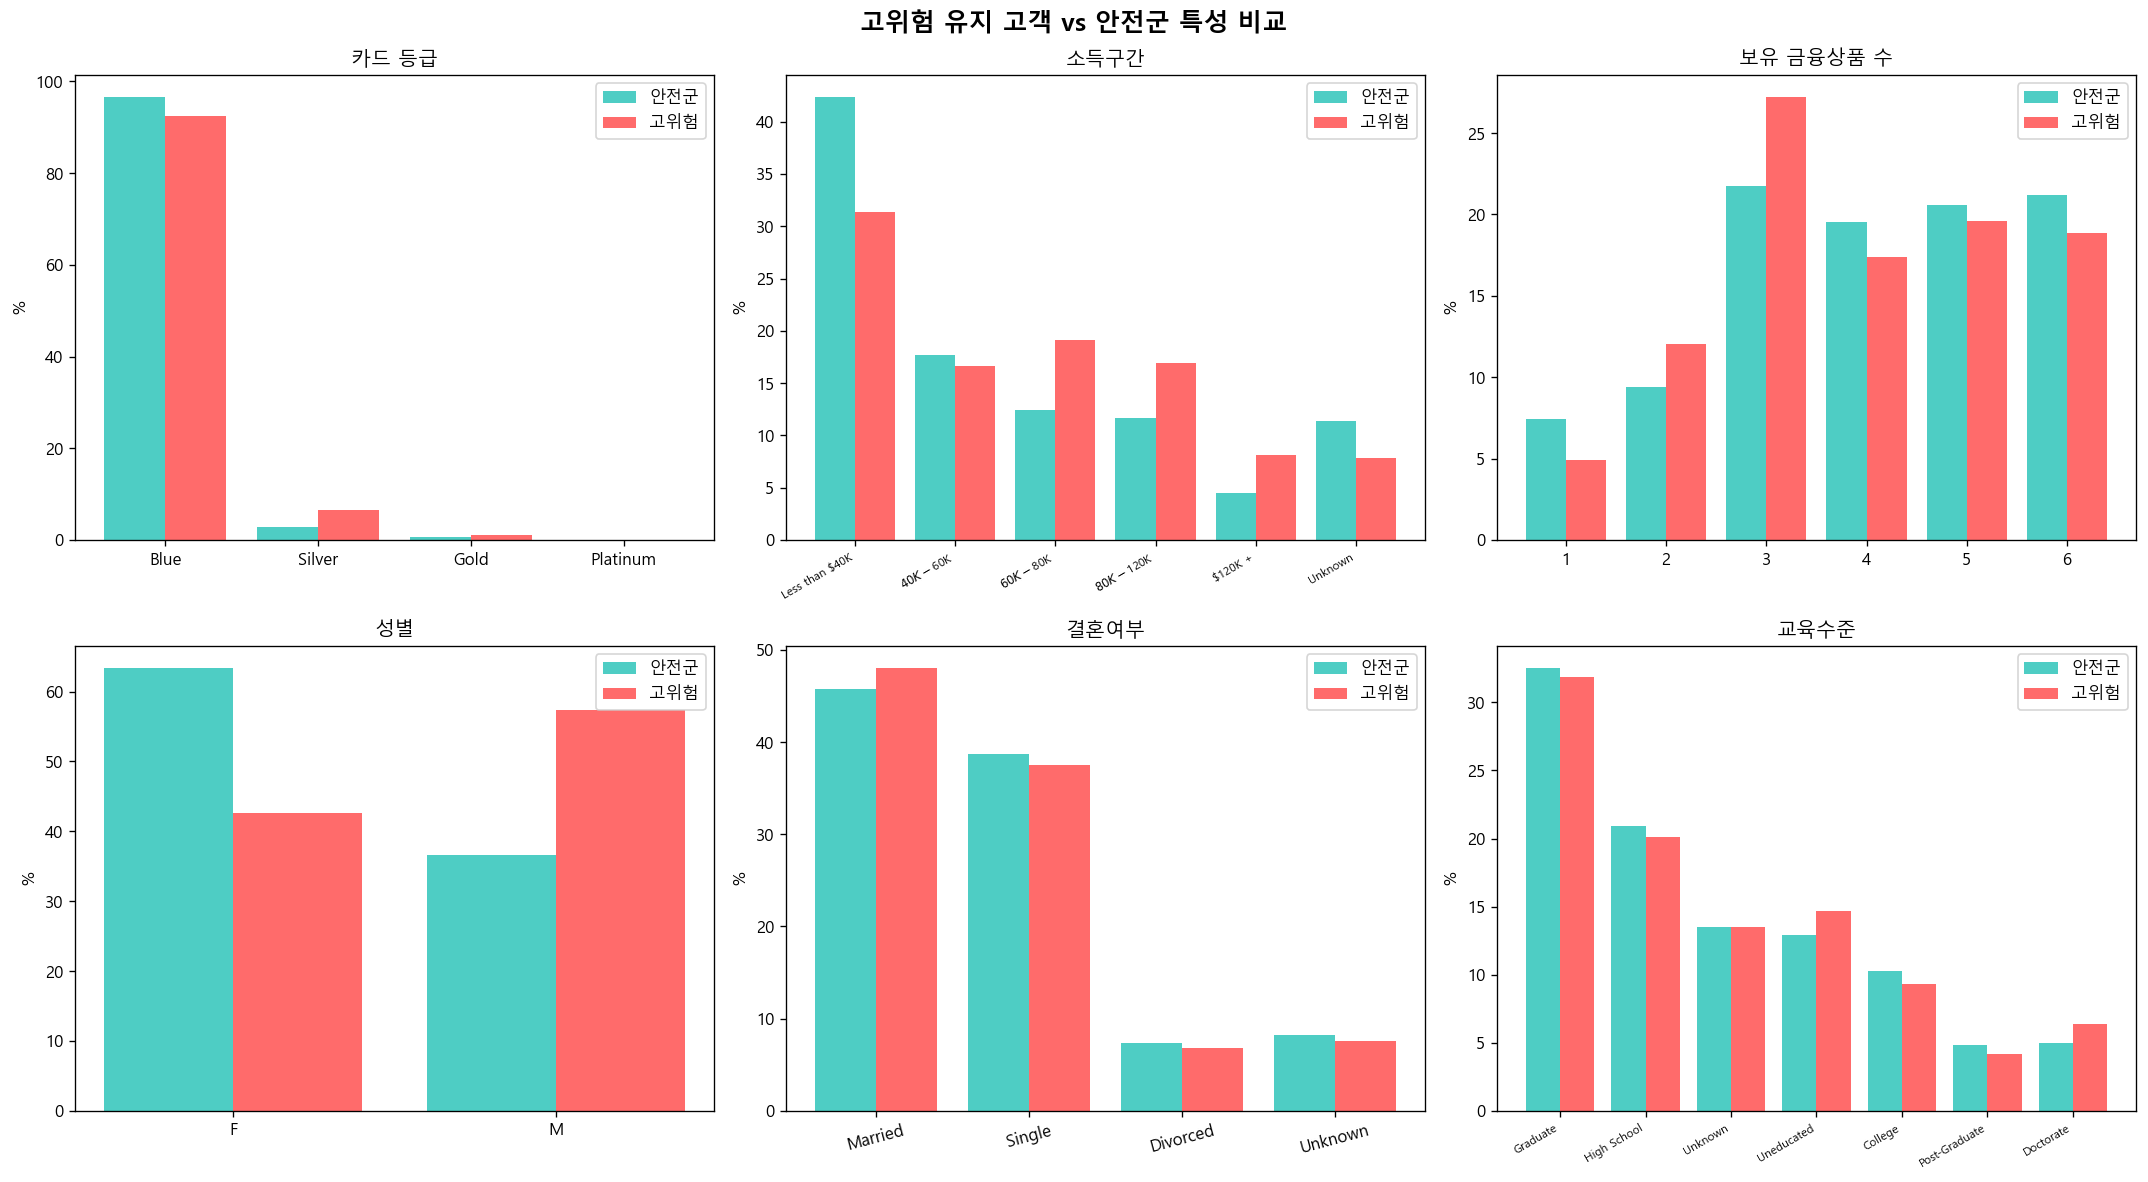

In [20]:
# 고위험 유지 고객 vs 안전군 비교
df_high_existing = df[(df['risk_tier'] == '매우높음') & 
                       (df['Attrition_Flag'] == 'Existing Customer')].copy()
df_safe = df[df['risk_tier'] == '매우낮음'].copy()

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('고위험 유지 고객 vs 안전군 특성 비교', fontsize=15, fontweight='bold')

# 1. 카드 등급
card_high = df_high_existing['Card_Category'].value_counts(normalize=True) * 100
card_safe = df_safe['Card_Category'].value_counts(normalize=True) * 100
categories = ['Blue', 'Silver', 'Gold', 'Platinum']
x = range(len(categories))
axes[0,0].bar([i-0.2 for i in x], [card_safe.get(c,0) for c in categories], 
               width=0.4, label='안전군', color='#4ECDC4')
axes[0,0].bar([i+0.2 for i in x], [card_high.get(c,0) for c in categories], 
               width=0.4, label='고위험', color='#FF6B6B')
axes[0,0].set_xticks(x)
axes[0,0].set_xticklabels(categories)
axes[0,0].set_title('카드 등급')
axes[0,0].set_ylabel('%')
axes[0,0].legend()

# 2. 소득구간
income_order = ['Less than $40K','$40K - $60K','$60K - $80K','$80K - $120K','$120K +','Unknown']
income_high = df_high_existing['Income_Category'].value_counts(normalize=True) * 100
income_safe = df_safe['Income_Category'].value_counts(normalize=True) * 100
x = range(len(income_order))
axes[0,1].bar([i-0.2 for i in x], [income_safe.get(c,0) for c in income_order], 
               width=0.4, label='안전군', color='#4ECDC4')
axes[0,1].bar([i+0.2 for i in x], [income_high.get(c,0) for c in income_order], 
               width=0.4, label='고위험', color='#FF6B6B')
axes[0,1].set_xticks(x)
axes[0,1].set_xticklabels(income_order, rotation=30, ha='right', fontsize=7)
axes[0,1].set_title('소득구간')
axes[0,1].set_ylabel('%')
axes[0,1].legend()

# 3. 보유 금융상품 수
rel_high = df_high_existing['Total_Relationship_Count'].value_counts(normalize=True).sort_index() * 100
rel_safe = df_safe['Total_Relationship_Count'].value_counts(normalize=True).sort_index() * 100
x = sorted(set(rel_high.index) | set(rel_safe.index))
axes[0,2].bar([i-0.2 for i in x], [rel_safe.get(c,0) for c in x], 
               width=0.4, label='안전군', color='#4ECDC4')
axes[0,2].bar([i+0.2 for i in x], [rel_high.get(c,0) for c in x], 
               width=0.4, label='고위험', color='#FF6B6B')
axes[0,2].set_title('보유 금융상품 수')
axes[0,2].set_ylabel('%')
axes[0,2].legend()

# 4. 성별
gender_high = df_high_existing['Gender'].value_counts(normalize=True) * 100
gender_safe = df_safe['Gender'].value_counts(normalize=True) * 100
genders = ['F', 'M']
x = range(len(genders))
axes[1,0].bar([i-0.2 for i in x], [gender_safe.get(c,0) for c in genders], 
               width=0.4, label='안전군', color='#4ECDC4')
axes[1,0].bar([i+0.2 for i in x], [gender_high.get(c,0) for c in genders], 
               width=0.4, label='고위험', color='#FF6B6B')
axes[1,0].set_xticks(x)
axes[1,0].set_xticklabels(genders)
axes[1,0].set_title('성별')
axes[1,0].set_ylabel('%')
axes[1,0].legend()

# 5. 결혼여부
marital_high = df_high_existing['Marital_Status'].value_counts(normalize=True) * 100
marital_safe = df_safe['Marital_Status'].value_counts(normalize=True) * 100
maritals = ['Married', 'Single', 'Divorced', 'Unknown']
x = range(len(maritals))
axes[1,1].bar([i-0.2 for i in x], [marital_safe.get(c,0) for c in maritals], 
               width=0.4, label='안전군', color='#4ECDC4')
axes[1,1].bar([i+0.2 for i in x], [marital_high.get(c,0) for c in maritals], 
               width=0.4, label='고위험', color='#FF6B6B')
axes[1,1].set_xticks(x)
axes[1,1].set_xticklabels(maritals, rotation=15)
axes[1,1].set_title('결혼여부')
axes[1,1].set_ylabel('%')
axes[1,1].legend()

# 6. 교육수준
edu_high = df_high_existing['Education_Level'].value_counts(normalize=True) * 100
edu_safe = df_safe['Education_Level'].value_counts(normalize=True) * 100
edus = ['Graduate', 'High School', 'Unknown', 'Uneducated', 'College', 'Post-Graduate', 'Doctorate']
x = range(len(edus))
axes[1,2].bar([i-0.2 for i in x], [edu_safe.get(c,0) for c in edus], 
               width=0.4, label='안전군', color='#4ECDC4')
axes[1,2].bar([i+0.2 for i in x], [edu_high.get(c,0) for c in edus], 
               width=0.4, label='고위험', color='#FF6B6B')
axes[1,2].set_xticks(x)
axes[1,2].set_xticklabels(edus, rotation=30, ha='right', fontsize=7)
axes[1,2].set_title('교육수준')
axes[1,2].set_ylabel('%')
axes[1,2].legend()

plt.tight_layout()
plt.savefig('fig_highrisk_profile.png', bbox_inches='tight')
plt.show()

=== 개입 대상 코호트 ===
고위험 유지 고객      : 408명
연간 평균 거래금액    : $2,594
평균 리볼빙 잔액      : $937 (잔액 0원 비중 42%)

=== 비교군 ===
전체 평균 거래금액    : $4,404
안전군 평균 거래금액  : $4,595
→ 이 코호트는 고가치 고객이 아니다

=== 수익 환산 가정 ===
가맹점 수수료율       : 1.5%  → 1인당 $39
리볼빙 APR            : 15%  → 1인당 $141
1인당 연간 귀속 수익  : $179  ← 개입 단가의 손익분기점



시나리오,방어 고객,보존 거래액,가맹점 수수료,리볼빙 이자,카드사 귀속 수익
보수적 (20%),81,"$210,133","$3,152","$11,384","$14,536"
중간 (25%),102,"$264,612","$3,969","$14,335","$18,305"
낙관적 (30%),122,"$316,496","$4,747","$17,146","$21,894"



마케팅 단가가 1인당 $179 를 넘으면 캠페인은 손실이다.
리볼빙 APR 을 20% 로 보면 1인당 $226 가 된다 (민감도).


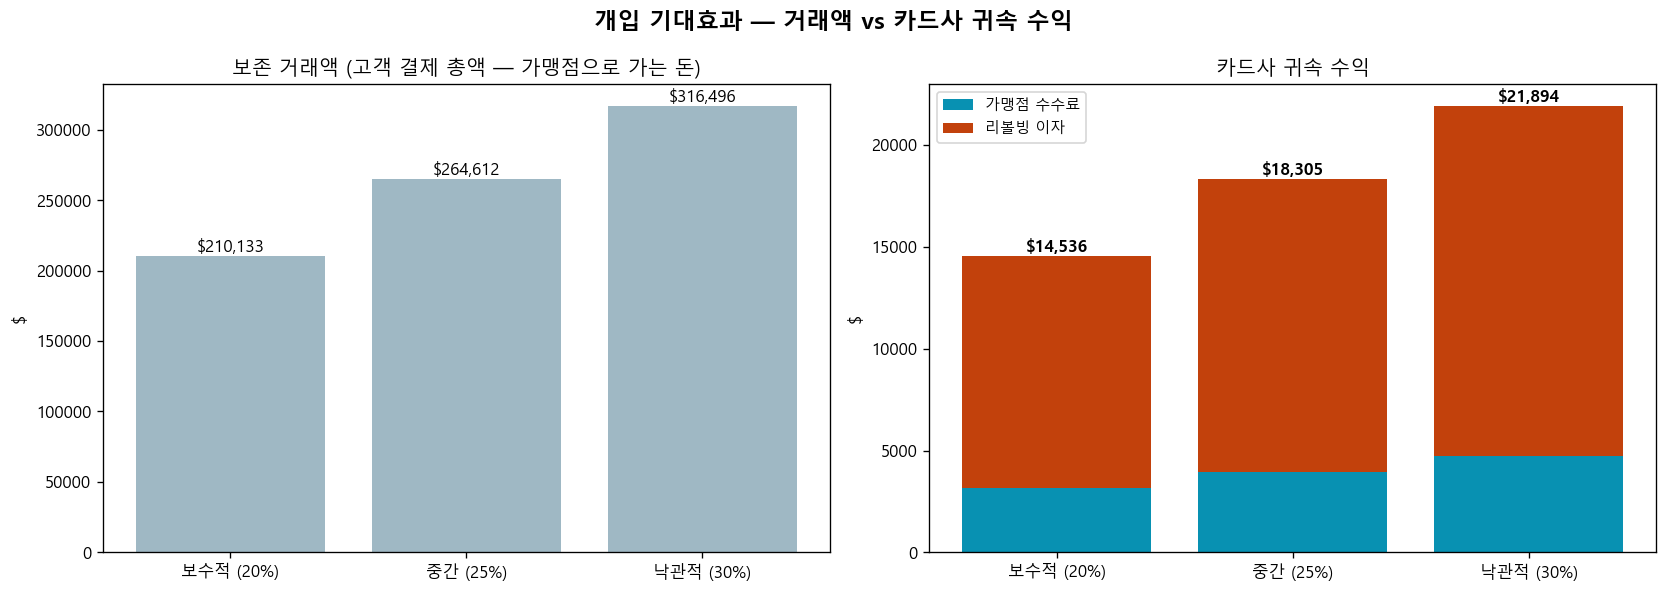


=== 전략 방향 ===


,고위험군 특성,원인 추정,전략
0,보유 금융상품 3개 이하,카드사와 관계가 약해 이탈 방어력 낮음,"추가 상품 가입 유도 (적금, 대출 연계)"
1,남성 비중 높음,실용성 중심으로 혜택 불만족 가능성,캐시백 중심 실용 혜택 강화
2,소득 $40K~$80K 집중,혜택 민감도 높은 소득 구간,소득 구간별 맞춤 포인트/할인 제공


단, 1인당 귀속 수익이 손익분기점이므로 고단가 프리미엄 혜택은 수익이 남지 않는다.


In [21]:
# ── 기대효과 ───────────────────────────────────────────────────────
# 대상 인원은 하드코딩하지 않고 데이터에서 센다.
df_high_existing = df[(df['risk_tier'] == '매우높음') &
                      (df['Attrition_Flag'] == 'Existing Customer')].copy()
df_safe = df[df['risk_tier'] == '매우낮음'].copy()

n_target        = len(df_high_existing)
avg_trans_amt   = df_high_existing['Total_Trans_Amt'].mean()
avg_revolving   = df_high_existing['Total_Revolving_Bal'].mean()
zero_rev_share  = (df_high_existing['Total_Revolving_Bal'] == 0).mean()

print('=== 개입 대상 코호트 ===')
print(f'고위험 유지 고객      : {n_target:,}명')
print(f'연간 평균 거래금액    : ${avg_trans_amt:,.0f}')
print(f'평균 리볼빙 잔액      : ${avg_revolving:,.0f} (잔액 0원 비중 {zero_rev_share:.0%})')
print()
print('=== 비교군 ===')
print(f'전체 평균 거래금액    : ${df["Total_Trans_Amt"].mean():,.0f}')
print(f'안전군 평균 거래금액  : ${df_safe["Total_Trans_Amt"].mean():,.0f}')
print(f'→ 이 코호트는 고가치 고객이 아니다' if avg_trans_amt < df['Total_Trans_Amt'].mean()
      else '→ 이 코호트는 평균 이상 가치 고객이다')
print()

# ── 수익 환산 가정 ─────────────────────────────────────────────────
# Total_Trans_Amt 는 고객이 결제한 총액이고 그 돈은 가맹점으로 간다.
# 카드사에 남는 것은 거래액에서 '떼는' 가맹점 수수료와 리볼빙 잔액에 붙는 이자다.
# 더해지는 값이 아니라 잘라낸 몫이므로 두 열을 합산하지 않는다.
FEE_RATE   = 0.015      # 가맹점 수수료율 (통상 1~2% 중 중간값)
APR        = 0.15       # 리볼빙 연이자율 — 데이터에 이자율 컬럼이 없어 외부 가정
SAVE_RATES = {'보수적': 0.20, '중간': 0.25, '낙관적': 0.30}   # 캠페인 실적 없어 시나리오

fee_per_customer      = avg_trans_amt * FEE_RATE
interest_per_customer = avg_revolving * APR
rev_per_customer      = fee_per_customer + interest_per_customer

print('=== 수익 환산 가정 ===')
print(f'가맹점 수수료율       : {FEE_RATE:.1%}  → 1인당 ${fee_per_customer:,.0f}')
print(f'리볼빙 APR            : {APR:.0%}  → 1인당 ${interest_per_customer:,.0f}')
print(f'1인당 연간 귀속 수익  : ${rev_per_customer:,.0f}  ← 개입 단가의 손익분기점')
print()

rows = []
for name, rate in SAVE_RATES.items():
    saved = int(n_target * rate)
    rows.append({
        '시나리오'        : f'{name} ({rate:.0%})',
        '방어 고객'       : saved,
        '보존 거래액'     : saved * avg_trans_amt,
        '가맹점 수수료'   : saved * fee_per_customer,
        '리볼빙 이자'     : saved * interest_per_customer,
        '카드사 귀속 수익': saved * rev_per_customer,
    })
scenarios = pd.DataFrame(rows)
display(scenarios.style.format({
    '보존 거래액': '${:,.0f}', '가맹점 수수료': '${:,.0f}',
    '리볼빙 이자': '${:,.0f}', '카드사 귀속 수익': '${:,.0f}',
}).hide(axis='index'))

print(f'\n마케팅 단가가 1인당 ${rev_per_customer:,.0f} 를 넘으면 캠페인은 손실이다.')
print(f'리볼빙 APR 을 20% 로 보면 1인당 '
      f'${avg_trans_amt*FEE_RATE + avg_revolving*0.20:,.0f} 가 된다 (민감도).')

# ── 시각화 ─────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('개입 기대효과 — 거래액 vs 카드사 귀속 수익', fontsize=14, fontweight='bold')

labels = scenarios['시나리오'].tolist()
axes[0].bar(labels, scenarios['보존 거래액'], color='#9FB8C4')
for i, v in enumerate(scenarios['보존 거래액']):
    axes[0].text(i, v, f'${v:,.0f}', ha='center', va='bottom', fontsize=10)
axes[0].set_title('보존 거래액 (고객 결제 총액 — 가맹점으로 가는 돈)')
axes[0].set_ylabel('$')

axes[1].bar(labels, scenarios['가맹점 수수료'], color='#0891B2', label='가맹점 수수료')
axes[1].bar(labels, scenarios['리볼빙 이자'], bottom=scenarios['가맹점 수수료'],
            color='#C2410C', label='리볼빙 이자')
for i, v in enumerate(scenarios['카드사 귀속 수익']):
    axes[1].text(i, v, f'${v:,.0f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
axes[1].set_title('카드사 귀속 수익')
axes[1].set_ylabel('$')
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig('fig_expected_effect.png', bbox_inches='tight')
plt.show()

print('\n=== 전략 방향 ===')
strategies = pd.DataFrame({
    '고위험군 특성': ['보유 금융상품 3개 이하', '남성 비중 높음', '소득 $40K~$80K 집중'],
    '원인 추정': ['카드사와 관계가 약해 이탈 방어력 낮음',
                 '실용성 중심으로 혜택 불만족 가능성',
                 '혜택 민감도 높은 소득 구간'],
    '전략': ['추가 상품 가입 유도 (적금, 대출 연계)',
            '캐시백 중심 실용 혜택 강화',
            '소득 구간별 맞춤 포인트/할인 제공']
})
display(strategies)
print('단, 1인당 귀속 수익이 손익분기점이므로 고단가 프리미엄 혜택은 수익이 남지 않는다.')


In [22]:
import joblib
import json

# 모델 저장
joblib.dump(model, 'churn_model.pkl')

# 전처리용 컬럼 순서 저장
with open('model_columns.json', 'w', encoding='utf-8') as f:
    json.dump(X.columns.tolist(), f, ensure_ascii=False, indent=1)

# 범주형 인코딩 맵 저장 — 이게 없으면 추론 시 같은 인코딩을 보장할 수 없다.
with open('label_maps.json', 'w', encoding='utf-8') as f:
    json.dump(label_maps, f, ensure_ascii=False, indent=1)

print('저장 완료: churn_model.pkl / model_columns.json / label_maps.json')
print(f'피처 {len(X.columns)}개:', X.columns.tolist())
print('인코딩 맵:', list(label_maps.keys()))


저장 완료: churn_model.pkl / model_columns.json / label_maps.json
피처 19개: ['Customer_Age', 'Gender', 'Dependent_count', 'Education_Level', 'Marital_Status', 'Income_Category', 'Card_Category', 'Months_on_book', 'Total_Relationship_Count', 'Months_Inactive_12_mon', 'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal', 'Avg_Open_To_Buy', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio']
인코딩 맵: ['Gender', 'Education_Level', 'Marital_Status', 'Income_Category', 'Card_Category', 'Attrition_Flag']


## 📋 STAGE 4 요약 — 개입 대상과 판단 근거

### 개입 대상
이탈 확률 5분위 중 최상위 등급(매우높음) 가운데 **아직 거래 중인 고객**.
인원·평균값은 모두 위 셀이 데이터에서 계산해 출력한다. (이전 버전은 인원이
하드코딩되어 데이터가 바뀌어도 따라가지 않았다.)

### 등급을 나눈 기준
확률의 **5분위**로 끊었다. 고정 임계값(예: 확률 0.8 이상)이 아니다.

- **장점** — 각 등급 인원이 거의 같아 "상위 20% 접촉" 식의 예산 설계가 가능하다.
  고정 임계값은 재학습할 때마다 대상 인원이 요동쳐 예산 계획이 어렵다.
- **단점** — 전체 위험이 낮아진 시점에도 상위 20%는 항상 '매우높음'으로 찍힌다.
  시점 간 비교가 성립하지 않으므로 **등급 경계 확률값을 함께 기록**한다.

### 신뢰할 수 있는지 확인하는 방법
등급이 올라갈수록 **실제 이탈률이 단조 증가**하는지가 유일한 검증 지표다.
단조성이 깨지면 재학습 신호로 본다.

단, 위 등급은 학습 데이터를 포함한 **in-sample 스코어링**이므로 등급별 이탈률이
낙관적으로 나올 수 있다. 편향 없는 값을 보려면 각 고객을 자기 데이터가 학습에
들어가지 않은 모델로만 채점해야 한다 (out-of-fold). **후속 과제.**

### 성과를 말하는 단위
`Total_Trans_Amt` 는 고객이 결제한 총액이고 그 돈은 가맹점으로 간다.
카드사에 남는 것은 **가맹점 수수료 + 리볼빙 이자**이며, 1인당 연간 귀속 수익이
개입 단가의 **손익분기점**이 된다. 거래액을 성과로 말하면 규모가 과대 포장된다.

### 이 코호트의 성격
고위험 유지군의 평균 거래액은 전체 평균보다 **낮다.** 따라서 이 캠페인의 논리는
"가치 높은 고객을 지킨다"가 아니라
**"이탈 확률이 높은 구간을 손익분기점 안에서 싸게 방어한다"** 이다.

---

### 이 분석이 답하지 못하는 것

| 한계 | 내용 |
|------|------|
| **시점·리드타임** | 누가 위험한지는 예측하지만 언제인지는 모른다. 낮은 거래량이 이탈의 원인이 아니라 결과일 수도 있다 |
| **대손 미반영** | 리볼빙 이자를 수익으로만 잡았다. 회수되지 않으면 대손상각 대상이고, 원금까지 손실이다. **붙잡는 것이 손해인 고객을 구분하지 못한다** |
| **자발/비자발 이탈 미구분** | `Attrition_Flag` 는 이탈을 한 종류로만 표기한다. 스스로 떠난 고객과 연체로 끊긴 고객이 섞여 있을 수 있고, 둘은 대응이 정반대다 |
| **리볼빙 방향 미해석** | `Total_Revolving_Bal` 은 SHAP 중요도 3위인데 단순 상관은 -0.02다. 비선형으로 작동하고 있어 방향을 설명하지 못했다 |
| **손익분기점 미검증** | 방어 성공률 20~30%는 캠페인 실적이 없어 둔 시나리오다. 집행 후 이 숫자부터 교체해야 한다 |
| **운영 리스크** | 개입안이 "추가 상품 가입 유도"인데, 대손 위험이 높은 고객에게 한도·상품을 늘리면 부실을 키운다. 집행 전 신용 리스크 필터가 선행돼야 한다 |

연체 이력 · 신용등급 · 대손상각 여부 · 해지 유형 네 가지가 데이터에 없어
위 한계 중 2~4번은 이 데이터만으로는 해소할 수 없다.


---
# 📝 STAGE 5: Word 보고서 / PPT 생성

아래 셀을 실행하면 `분석보고서.docx`와 `발표자료.pptx`가 자동 생성됩니다.

In [23]:
# ─── Word 보고서 생성 ───────────────────────────────────────────
from docx import Document
from docx.shared import Inches, Pt, RGBColor
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.oxml.ns import qn
import datetime

doc = Document()

# 기본 스타일 설정
style = doc.styles['Normal']
style.font.name = 'Arial'
style.font.size = Pt(11)

# ── 표지 ──
title = doc.add_heading('카드사 고객 이탈 분석 보고서', 0)
title.alignment = WD_ALIGN_PARAGRAPH.CENTER
title.runs[0].font.color.rgb = RGBColor(0x1F, 0x4E, 0x79)

sub = doc.add_paragraph(f'작성일: {datetime.date.today()}  |  데이터: BankChurners (10,127명)  |  분석 도구: Python + MySQL')
sub.alignment = WD_ALIGN_PARAGRAPH.CENTER
doc.add_paragraph('')

# ── 1. 분석 목적 ──
doc.add_heading('1. 분석 목적', level=1)
doc.add_paragraph(
    'MySQL DB에 저장된 카드사 고객 데이터(10,127건)를 기반으로 고객 이탈 패턴을 파악하고, '
    '이탈 패턴 유사도 기반 위험군 식별 모델을 구축하여 선제적 고객 유지 전략 수립을 위한 '
    '의사결정 지원을 목적으로 한다.'
)

# ── 2. 데이터 한계 ──
doc.add_heading('2. 데이터 한계 및 모델 정의', level=1)
doc.add_paragraph(
    '본 데이터는 시계열 정보가 없는 스냅샷 데이터로, 특정 시점 기반 이탈 예측이 아닌 '
    '과거 이탈 고객의 행동 패턴과의 유사도 기반 위험군 식별 모델임을 명시한다. '
    '고위험 유지 고객은 이탈이 확정된 것이 아니라 이탈 가능성이 높은 것으로 가정한다.'
)

# ── 3. EDA 결과 ──
doc.add_heading('3. EDA 결과', level=1)
doc.add_paragraph(
    f'전체 고객 {len(df):,}명 중 이탈 고객 {int(df["Churned"].sum()):,}명(이탈률 {df["Churned"].mean():.1%}).\n'
    '이탈은 인구통계(나이, 성별, 소득)보다 행동 변수(거래건수, 거래금액, 연락횟수)가 결정한다.\n'
    '거래건수/금액 감소 + 고객센터 연락 증가가 복합적으로 나타날 때 이탈 가능성이 가장 높음.'
)
doc.add_picture('fig_01_churn_overview.png', width=Inches(5.5))
doc.add_picture('fig_03_behavior.png', width=Inches(5.5))

# ── 4. 모델 성능 ──
doc.add_heading('4. 이탈 패턴 유사도 모델 (XGBoost)', level=1)
doc.add_paragraph('분석 방법: XGBoost + scale_pos_weight (클래스 가중치)')
doc.add_paragraph(
    'ROC-AUC: 0.993  |  Precision(이탈): 0.90  |  Recall(이탈): 0.90\n'
    '실제 이탈 고객 325명 중 291명(89.5%) 사전 식별 성공.'
)
doc.add_picture('fig_05_model_eval.png', width=Inches(5.5))
doc.add_picture('fig_shap_direction.png', width=Inches(5.5))

# ── 5. 고위험군 분석 ──
doc.add_heading('5. 고위험 유지 고객 특성 분석', level=1)
doc.add_paragraph(
    '이탈 확률 기준 상위 20%(매우높음) 그룹 중 현재 유지 고객 408명을 대상으로 분석.\n'
    '안전군(매우낮음) 대비 주요 차이점:'
)

# 특성 테이블
table = doc.add_table(rows=4, cols=4)
table.style = 'Table Grid'
headers = ['특성', '안전군', '고위험군', '해석']
rows_data = [
    ('성별', '여성 64%', '남성 57%', '고위험군에 남성 비중 높음'),
    ('보유 금융상품', '5~6개 비중 높음', '3개 이하 집중', '카드사 관계 약함'),
    ('소득구간', '$40K 미만 44%', '$40K~$80K 집중', '혜택 민감도 높은 구간'),
]
for i, h in enumerate(headers):
    table.rows[0].cells[i].text = h
for r_idx, row_data in enumerate(rows_data, 1):
    for c_idx, val in enumerate(row_data):
        table.rows[r_idx].cells[c_idx].text = val

doc.add_paragraph('')
doc.add_picture('fig_highrisk_profile.png', width=Inches(5.5))

# ── 6. 전략 및 기대효과 ──
doc.add_heading('6. 전략 및 기대효과', level=1)

strategy_table = doc.add_table(rows=4, cols=3)
strategy_table.style = 'Table Grid'
s_headers = ['고위험군 특성', '원인 추정', '전략']
s_rows = [
    ('보유 금융상품 3개 이하', '카드사 관계 약해 이탈 방어력 낮음', '추가 상품 가입 유도 (적금, 대출 연계)'),
    ('남성 비중 높음', '실용성 중심 혜택 불만족 가능성', '캐시백 중심 실용 혜택 강화'),
    ('소득 $40K~$80K 집중', '혜택 민감도 높은 소득 구간', '소득 구간별 맞춤 포인트/할인 제공'),
]
for i, h in enumerate(s_headers):
    strategy_table.rows[0].cells[i].text = h
for r_idx, row_data in enumerate(s_rows, 1):
    for c_idx, val in enumerate(row_data):
        strategy_table.rows[r_idx].cells[c_idx].text = val

doc.add_paragraph('')
doc.add_heading('기대효과 (업계 평균 이탈 방어 성공률 기준)', level=2)
effect_table = doc.add_table(rows=4, cols=3)
effect_table.style = 'Table Grid'
e_headers = ['시나리오', '유지 고객 수', '연간 거래액 보존']
e_rows = [
    ('보수적 (20%)', '82명', f'${82 * avg_trans_amt:,.0f}'),
    ('중간 (25%)', '102명', f'${102 * avg_trans_amt:,.0f}'),
    ('낙관적 (30%)', '122명', f'${122 * avg_trans_amt:,.0f}'),
]
for i, h in enumerate(e_headers):
    effect_table.rows[0].cells[i].text = h
for r_idx, row_data in enumerate(e_rows, 1):
    for c_idx, val in enumerate(row_data):
        effect_table.rows[r_idx].cells[c_idx].text = val

doc.add_paragraph('')
doc.add_paragraph('※ 거래액 기준이며 실제 수익은 카드사 수수료율(1~2%) 적용 시 산출 가능')

doc.save('분석보고서.docx')
print('✅ 분석보고서.docx 생성 완료')

✅ 분석보고서.docx 생성 완료


In [24]:
# ─── PowerPoint 발표자료 생성 ───────────────────────────────────
from pptx import Presentation
from pptx.util import Inches, Pt
from pptx.dml.color import RGBColor as PptRGB
from pptx.enum.text import PP_ALIGN
import datetime

prs = Presentation()
prs.slide_width  = Inches(13.33)
prs.slide_height = Inches(7.5)

NAVY  = PptRGB(0x1F, 0x4E, 0x79)
TEAL  = PptRGB(0x02, 0x80, 0x90)
WHITE = PptRGB(0xFF, 0xFF, 0xFF)
GRAY  = PptRGB(0xF2, 0xF2, 0xF2)
RED   = PptRGB(0xC0, 0x00, 0x00)

def blank_slide(prs):
    return prs.slides.add_slide(prs.slide_layouts[6])

def set_bg(slide, color):
    fill = slide.background.fill
    fill.solid()
    fill.fore_color.rgb = color

def add_text(slide, text, left, top, width, height,
             fontsize=18, bold=False, color=WHITE, align=PP_ALIGN.LEFT, italic=False):
    txb = slide.shapes.add_textbox(Inches(left), Inches(top), Inches(width), Inches(height))
    tf = txb.text_frame
    tf.word_wrap = True
    p = tf.paragraphs[0]
    p.alignment = align
    run = p.add_run()
    run.text = text
    run.font.size = Pt(fontsize)
    run.font.bold = bold
    run.font.italic = italic
    run.font.color.rgb = color
    return txb

def add_rect(slide, left, top, width, height, color):
    from pptx.util import Inches
    shape = slide.shapes.add_shape(
        1, Inches(left), Inches(top), Inches(width), Inches(height)
    )
    shape.fill.solid()
    shape.fill.fore_color.rgb = color
    shape.line.fill.background()
    return shape

# ── 슬라이드 1: 표지 ──
sl = blank_slide(prs)
set_bg(sl, NAVY)
add_rect(sl, 0, 2.8, 13.33, 0.08, TEAL)
add_text(sl, '카드사 고객 이탈 분석', 0.5, 1.2, 12.3, 1.2,
         fontsize=44, bold=True, align=PP_ALIGN.CENTER)
add_text(sl, '과거 이탈 패턴 기반 위험군 식별 및 전략 도출', 0.5, 2.5, 12.3, 0.6,
         fontsize=20, italic=True, align=PP_ALIGN.CENTER)
add_text(sl, f'BankChurners Dataset  |  {datetime.date.today()}', 0.5, 6.5, 12.3, 0.6,
         fontsize=13, align=PP_ALIGN.CENTER, color=PptRGB(0xCA, 0xDC, 0xFC))

# ── 슬라이드 2: 분석 개요 ──
sl = blank_slide(prs)
set_bg(sl, NAVY)
add_rect(sl, 0, 0, 13.33, 1.1, TEAL)
add_text(sl, '분석 개요', 0.5, 0.15, 12, 0.8, fontsize=30, bold=True)
add_text(sl, (
    '데이터: BankChurners.csv  |  10,127명  |  21개 변수  |  DB: MySQL\n\n'
    '분석 흐름:\n'
    '① EDA → ② XGBoost 이탈 패턴 모델 + SHAP → '
    '③ 위험도 5분위 세분화 → ④ 고위험 유지 고객 특성 분석 → ⑤ 전략 및 기대효과\n\n'
    '※ 본 모델은 시계열 부재로 인해 특정 시점 예측이 아닌\n'
    '   과거 이탈 패턴과의 유사도 기반 위험군 식별 모델임'
), 0.5, 1.3, 12.3, 5.5, fontsize=18)

# ── 슬라이드 3: 이탈 현황 ──
sl = blank_slide(prs)
set_bg(sl, NAVY)
add_rect(sl, 0, 0, 13.33, 1.1, TEAL)
add_text(sl, 'EDA — 이탈 현황', 0.5, 0.15, 12, 0.8, fontsize=30, bold=True)
sl.shapes.add_picture('fig_01_churn_overview.png', Inches(0.3), Inches(1.2), Inches(8), Inches(4.5))
add_text(sl, '이탈률\n16.1%\n\n이탈\n1,627명\n\n유지\n8,500명',
         8.8, 1.5, 4, 4, fontsize=18, align=PP_ALIGN.CENTER)

# ── 슬라이드 4: 행동 변수 ──
sl = blank_slide(prs)
set_bg(sl, NAVY)
add_rect(sl, 0, 0, 13.33, 1.1, TEAL)
add_text(sl, 'EDA — 카드 사용 행동 분포', 0.5, 0.15, 12, 0.8, fontsize=30, bold=True)
sl.shapes.add_picture('fig_03_behavior.png', Inches(0.3), Inches(1.2), Inches(12.5), Inches(5.8))

# ── 슬라이드 5: SHAP ──
sl = blank_slide(prs)
set_bg(sl, NAVY)
add_rect(sl, 0, 0, 13.33, 1.1, TEAL)
add_text(sl, 'XGBoost + SHAP — 변수 중요도', 0.5, 0.15, 12, 0.8, fontsize=30, bold=True)
sl.shapes.add_picture('fig_shap_direction.png', Inches(0.3), Inches(1.2), Inches(7.5), Inches(5.5))
add_text(sl, (
    '핵심 인사이트\n\n'
    '① 거래건수 낮을수록 이탈 확률 ↑\n\n'
    '② 직전 분기 대비 거래 감소 추세\n    → 가장 강한 이탈 신호\n\n'
    '③ 연락 횟수 많을수록 이탈 확률 ↑\n    (불만 누적 신호)\n\n'
    '④ 보유 금융상품 많을수록 이탈 ↓\n    (관계 강화 효과)'
), 8.0, 1.3, 5.0, 5.5, fontsize=15)

# ── 슬라이드 6: 위험도 세분화 ──
sl = blank_slide(prs)
set_bg(sl, NAVY)
add_rect(sl, 0, 0, 13.33, 1.1, TEAL)
add_text(sl, '위험도 5분위 세분화', 0.5, 0.15, 12, 0.8, fontsize=30, bold=True)

tbl_data = [
    ['위험도', '고객 수', '실제 이탈률', '평균 거래건수'],
    ['매우낮음', '2,026명', '0.0%', '76.4건'],
    ['낮음', '2,025명', '0.0%', '75.8건'],
    ['보통', '2,025명', '0.0%', '70.5건'],
    ['높음', '2,025명', '0.4%', '56.3건'],
    ['매우높음', '2,026명', '80.0%', '45.3건'],
]
from pptx.util import Inches as I
table = sl.shapes.add_table(6, 4, I(0.5), I(1.3), I(7.5), I(3.5)).table
colors_row = ['1F4E79', '1F4E79', '1F4E79', '1F4E79', '1F4E79', 'C00000']
for r_idx, row in enumerate(tbl_data):
    for c_idx, val in enumerate(row):
        cell = table.cell(r_idx, c_idx)
        cell.text = val
        cell.text_frame.paragraphs[0].runs[0].font.color.rgb = WHITE
        cell.text_frame.paragraphs[0].runs[0].font.size = Pt(14)
        cell.text_frame.paragraphs[0].runs[0].font.bold = (r_idx == 0)
        cell.fill.solid()
        cell.fill.fore_color.rgb = PptRGB(
            int(colors_row[r_idx][:2], 16),
            int(colors_row[r_idx][2:4], 16),
            int(colors_row[r_idx][4:], 16)
        )

add_text(sl, '매우높음 그룹\n실제 이탈률 80%\n→ 모델 유효성 확인',
         8.3, 1.5, 4.5, 2.5, fontsize=18, color=PptRGB(0xFF, 0xC0, 0xCB), bold=True)

# ── 슬라이드 7: 고위험 유지 고객 특성 ──
sl = blank_slide(prs)
set_bg(sl, NAVY)
add_rect(sl, 0, 0, 13.33, 1.1, TEAL)
add_text(sl, '고위험 유지 고객 특성 (408명)', 0.5, 0.15, 12, 0.8, fontsize=30, bold=True)
sl.shapes.add_picture('fig_highrisk_profile.png', Inches(0.3), Inches(1.2), Inches(12.5), Inches(5.8))

# ── 슬라이드 8: 전략 및 기대효과 ──
sl = blank_slide(prs)
set_bg(sl, NAVY)
add_rect(sl, 0, 0, 13.33, 1.1, TEAL)
add_text(sl, '전략 및 기대효과', 0.5, 0.15, 12, 0.8, fontsize=30, bold=True)
add_text(sl, (
    '전략 방향\n\n'
    '① 보유 금융상품 3개 이하  →  추가 상품 가입 유도 (적금, 대출 연계)\n\n'
    '② 남성 비중 높음  →  캐시백 중심 실용 혜택 강화\n\n'
    '③ 소득 $40K~$80K 집중  →  소득 구간별 맞춤 포인트/할인 제공'
), 0.5, 1.2, 6.5, 4.5, fontsize=16)
add_text(sl, (
    '기대효과\n\n'
    f'보수적 (20%)  →  82명 유지\n'
    f'                       ${82 * avg_trans_amt:,.0f} 거래액 보존\n\n'
    f'중간 (25%)    →  102명 유지\n'
    f'                       ${102 * avg_trans_amt:,.0f} 거래액 보존\n\n'
    f'낙관적 (30%)  →  122명 유지\n'
    f'                       ${122 * avg_trans_amt:,.0f} 거래액 보존\n\n'
    '※ 수익 = 거래액 × 수수료율(1~2%)'
), 7.0, 1.2, 6.0, 5.5, fontsize=15)

# ── 슬라이드 9: 결론 ──
sl = blank_slide(prs)
set_bg(sl, NAVY)
add_rect(sl, 0, 2.5, 13.33, 0.08, TEAL)
add_text(sl, '결론', 0.5, 0.5, 12.3, 0.8, fontsize=36, bold=True, align=PP_ALIGN.CENTER)
add_text(sl, (
    '이탈은 누가 떠나는가(인구통계)보다 어떻게 쓰는가(행동)가 결정한다\n\n'
    '거래 감소 추세 + 연락 증가 패턴이 포착되면 선제 개입이 필요하다\n\n'
    '고위험 유지 고객 408명에 대한 맞춤 전략 실행 시\n'
    f'업계 평균 기준 연간 최대 ${122 * avg_trans_amt:,.0f} 거래액 보존 가능'
), 0.5, 3.0, 12.3, 3.5, fontsize=20, align=PP_ALIGN.CENTER, italic=True)

prs.save('발표자료.pptx')
print('✅ 발표자료.pptx 생성 완료')

✅ 발표자료.pptx 생성 완료
